# Biến động loại rừng trong các khu bảo tồn Việt Nam (ForTy V2 Beta, 2017–2025)

Notebook này:
1. lấy các khu bảo tồn (PA) của Việt Nam từ `WCMC/WDPA/current/polygons`;
2. vẽ bản đồ loại rừng năm 2017 và 2025 cho từng PA (ảnh tĩnh) và bản đồ thay đổi 2017 → 2025 tính ở 10 m;
3. tính diện tích từng loại rừng của mỗi PA cho các năm 2017–2025 từ `projects/nature-trace/assets/forest_typology/v2_beta/<năm>` và vẽ biểu đồ đường (line chart);
4. dùng Gemini viết nhận xét ngắn về biến động của mỗi PA;
5. xuất báo cáo HTML `outputs/bao_cao_ForTy_PA_VN.html`.

Mọi kết quả trung gian được lưu trong `outputs/` (diện tích, ảnh, nhận xét AI). Khi chạy lại, notebook chỉ tính những phần còn thiếu.

**Chuẩn bị:** Earth Engine đã đăng nhập (`earthengine authenticate`, project `ee-hoangvietanh`), biến môi trường `GEMINI_API_KEY` đã đặt (không ghi key vào notebook). Kernel: `.venv` của thư mục này.

## 1. Cấu hình

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

CFG = {
    "PROJECT": "ee-hoangvietanh",
    "YEARS": list(range(2017, 2026)),
    "MAP_YEARS": [2017, 2025],             # hai năm vẽ bản đồ
    # Chọn khu bảo tồn từ WDPA
    "PA_FILTER": {"iso3": "VNM",
                  "status": ("Designated", "Inscribed"),        # bỏ khu "Proposed"
                  "desig_types": ("National", "International"), # bỏ "International" nếu không muốn UNESCO-MAB/Ramsar
                  "exclude_realm": ("Marine",),                 # bỏ khu thuần biển
                  "min_land_km2": 1.0},
    "SITE_IDS": None,      # danh sách SITE_ID để chỉ chạy các khu này, ví dụ [10345, 18033]
    "PA_LIMIT": None,      # số khu tối đa (để chạy thử), None = tất cả
    "AREA_SCALES": (10, 20, 30),  # độ phân giải tính diện tích (m); chỉ dùng mức thô hơn khi mức mịn bị lỗi
    "GEE_WORKERS": 6,
    "THUMB_DIMS": 900,     # kích thước cạnh dài ảnh bản đồ (px)
    "LLM": {"MODEL": "auto",           # "auto" = model gemini-X.Y-flash cao nhất key dùng được
            "API_KEY_ENV": "GEMINI_API_KEY", "WORKERS": 4},
    "SHOW_IN_NOTEBOOK": 10,  # số khu hiển thị trong notebook (báo cáo HTML luôn có tất cả)
    "EMBED_IMAGES": True,    # bản trong outputs/: nhúng ảnh (1 file duy nhất); False = ảnh riêng trong outputs/img/
    "OUT": ROOT / "outputs",
    "PAGES_DIR": ROOT / "docs",  # bản cho GitHub Pages: docs/index.html + docs/img/
}
OUT = CFG["OUT"]
for d in ("areas", "transitions", "thumbs", "maps", "charts", "llm_cache"):
    (OUT / d).mkdir(parents=True, exist_ok=True)

In [2]:
import ee
import pandas as pd
from IPython.display import Image, Markdown, display

from fortypa import charts, gee, llm, report

pd.set_option("display.max_rows", 300, "display.width", 200)
gee.init(CFG["PROJECT"])
print("Earth Engine OK")

Earth Engine OK


## 2. Chú giải ForTy V2 Beta

Mỗi năm là một ImageCollection 10 m chia ô, ghép (mosaic) thành một ảnh. 7 band uint8 là xác suất từng lớp (0–250). Lớp của pixel = band có giá trị lớn nhất + 1. Lớp 6 (Đất khác) không phải rừng: trên bản đồ tô xám nhạt, trong biểu đồ không vẽ.
*V2 Beta là dữ liệu thử nghiệm; thứ tự band và định nghĩa lớp có thể thay đổi.*

**Tài liệu tham khảo**
- Neumann, M., Raichuk, A., Potapov, P. et al. Global forest typology at 10-meter resolution for forest and land-use monitoring. *Sci Data* 13, 1434 (2026). https://doi.org/10.1038/s41597-026-08299-5
- Google DeepMind. Beyond tree cover: mapping the world’s forest types. https://deepmind.google/blog/beyond-tree-cover-mapping-the-worlds-forest-types/

In [3]:
gee.CLASSES

,value,band,label,label_en,color
0,1,B0,Rừng nguyên sinh – trưởng thành,Primary forest: mature,#16733A
1,7,B6,Rừng nguyên sinh – đang phục hồi,Primary forest: regrowing,#33A17F
2,2,B1,Rừng tái sinh tự nhiên,Naturally regenerating forest,#A0B82B
3,3,B2,Rừng trồng (luân kỳ > 40 năm),Planted forest,#2C7FB8
4,4,B3,Rừng trồng thâm canh (luân kỳ ≤ 40 năm),Plantation forest,#C2408F
5,5,B4,Cây công nghiệp và nông lâm kết hợp,Tree crops and agroforestry,#D08C00
6,6,B5,Đất khác (không phải rừng),Other land (non-forest),#E4E4DF


## 3. Khu bảo tồn Việt Nam (WDPA)

In [4]:
fc, pas = gee.select_pas(**CFG["PA_FILTER"])
if CFG["SITE_IDS"]:
    pas = pas[pas.SITE_ID.isin(CFG["SITE_IDS"])]
if CFG["PA_LIMIT"]:
    pas = pas.head(CFG["PA_LIMIT"])
pas = pas.reset_index(drop=True)
fc = fc.filter(ee.Filter.inList("SITE_ID", pas.SITE_ID.tolist()))
pas.to_csv(OUT / "khu_bao_ton.csv", index=False, encoding="utf-8-sig")
print(f"{len(pas)} khu bảo tồn, tổng {pas.GIS_AREA.sum() * 100:,.0f} ha")
display(pas.groupby(["DESIG_TYPE", "DESIG_ENG"]).size().rename("số khu").to_frame())
pas[["SITE_ID", "NAME", "NAME_ENG", "DESIG_ENG", "IUCN_CAT", "STATUS_YR", "GIS_AREA"]]

156 khu bảo tồn, tổng 6,675,152 ha


số khu
DESIG_TYPE    DESIG_ENG                                                
International UNESCO-MAB Biosphere Reserve                            8
              Wetland of International Importance (Ramsar Site)       6
              World Heritage Site (natural or mixed)                  2
National      Cultural and Historical Site                           29
              Marine Protected Area                                  13
              National Park                                          30
              Nature Reserve                                         68

,SITE_ID,NAME,NAME_ENG,DESIG_ENG,IUCN_CAT,STATUS_YR,GIS_AREA
0,7877,Cát Bà,Cat Ba,National Park,II,1986,116.482411
1,7878,Cúc Phương,Cuc Phuong,National Park,II,1962,223.459522
2,10110,Bạch Mã,Bach Ma,National Park,II,1986,373.380261
3,10111,Côn Đảo,Con Dao,National Park,II,1993,72.742807
4,10113,Vườn quốc gia Ba Vì,Ba Vi,National Park,II,2003,118.985128
5,10114,Ngoc Trao,Ngoc Trao,Cultural and Historical Site,V,1986,16.671472
6,10117,Đền Hùng,Den Hung,Cultural and Historical Site,V,1977,28.592371
7,10127,Bắc Sơn,Bac Son,Nature Reserve,V,2013,18.099866
8,10187,Bán đảo Sơn Trà,Ban dao Son Tra,Nature Reserve,Not Reported,1992,38.150875
9,10188,Vườn quốc gia Ba Bể,Ba Be,National Park,Not Reported,1992,99.413330


### Chồng lấn giữa các khu

Các khu quốc tế (UNESCO-MAB, Ramsar, Di sản) thường bao trùm Vườn quốc gia/Khu bảo tồn quốc gia. Bảng dưới liệt kê các cặp giao nhau để quyết định có loại bớt khu nào không (sửa `PA_FILTER` hoặc `SITE_IDS` ở mục 1). Hiện tại mỗi khu được tính riêng.

In [5]:
ov_path = OUT / "chong_lan.csv"
try:
    ov = gee.overlaps(fc, pas)
    ov.to_csv(ov_path, index=False, encoding="utf-8-sig")
except Exception as e:
    ov = None
    print("Không tính được chồng lấn:", type(e).__name__, str(e)[:200])
if ov is not None:
    print(f"{len(ov)} cặp khu giao nhau")
    display(ov.head(30).round(1))

41 cặp khu giao nhau


,a,b,km2,name_a,name_b,desig_a,desig_b,pct_of_a,pct_of_b
0,61595,478289,943.5,Pù Mát,Tây Nghệ An,National Park,UNESCO-MAB Biosphere Reserve,97.2,7.3
1,303072,478280,701.4,Cát Tiên,Cát Tiên,National Park,UNESCO-MAB Biosphere Reserve,100.0,10.6
2,478280,555594129,433.4,Cát Tiên,Văn hóa Đồng Nai,UNESCO-MAB Biosphere Reserve,Nature Reserve,6.5,73.4
3,303024,478289,421.3,Pù Huống,Tây Nghệ An,Nature Reserve,UNESCO-MAB Biosphere Reserve,100.0,3.2
4,303088,478284,412.7,Phú Quốc,Kiên Giang,Marine Protected Area,UNESCO-MAB Biosphere Reserve,100.0,3.6
5,303023,478289,349.4,Pù Hoạt,Tây Nghệ An,Nature Reserve,UNESCO-MAB Biosphere Reserve,99.4,2.7
6,10398,478284,321.5,Phú Quốc,Kiên Giang,National Park,UNESCO-MAB Biosphere Reserve,100.0,2.8
7,303093,900889,310.8,Dao Cat Ba,Baie d'Ha-Long,Marine Protected Area,World Heritage Site (natural or mixed),80.3,46.1
8,10398,303088,275.0,Phú Quốc,Phú Quốc,National Park,Marine Protected Area,85.9,66.9
9,478277,900889,149.7,Cát Bà,Baie d'Ha-Long,UNESCO-MAB Biosphere Reserve,World Heritage Site (natural or mixed),56.9,22.2


## 4. Diện tích từng loại rừng theo năm

Một request cho mỗi khu, cả 9 năm cùng lúc (`frequencyHistogram`, hệ UTM của khu, 10 m). Kết quả mỗi khu lưu ở `outputs/areas/` nên chạy lại không tính lại.

In [6]:
t0 = time.time()
areas, failed = gee.compute_areas(fc, pas, CFG["YEARS"], OUT / "areas", scales=CFG["AREA_SCALES"],
                                  workers=CFG["GEE_WORKERS"])
print(f"Xong sau {time.time() - t0:.0f}s; lỗi: {len(failed)} khu")
areas = areas[areas.SITE_ID.isin(pas.SITE_ID)]
long = areas.merge(pas[["SITE_ID", "NAME", "DESIG_ENG"]], on="SITE_ID")
long.to_csv(OUT / "dien_tich_loai_rung_dai.csv", index=False, encoding="utf-8-sig")
wide = long.pivot_table(index=["SITE_ID", "NAME", "year"], columns="label", values="area_ha", aggfunc="sum").fillna(0)
wide.to_csv(OUT / "dien_tich_loai_rung.csv", encoding="utf-8-sig")
wide.head(18).round(1)

Diện tích: 156 PA lấy từ cache, 0 PA cần tính trên GEE
Xong sau 0s; lỗi: 0 khu


label                    Cây công nghiệp và nông lâm kết hợp  Rừng nguyên sinh – trưởng thành  Rừng nguyên sinh – đang phục hồi  Rừng trồng (luân kỳ > 40 năm)  \
SITE_ID NAME       year                                                                                                                                          
7877    Cát Bà     2017                                  9.0                            741.2                               0.0                            0.0   
                   2018                                  9.1                            741.2                               0.0                            0.0   
                   2019                                  9.2                            741.2                               0.0                            0.0   
                   2020                                  9.0                            741.2                               0.0                            0.0   
                   2021                                  8.7                            741.2                               0.0                            0.0   
                   2022                                  8.7                            741.2                               0.0                            0.0   
                   2023                                  8.6                            741.2                               0.0                            0.0   
                   2024                                  8.3                            741.2                               0.0                            0.0   
                   2025                                  8.3                            741.1                               0.0                            0.0   
7878    Cúc Phương 2017                                 46.7                          12653.1                               0.0                            0.0   
                   2018                                 46.8                          12653.1                               0.0                            0.0   
                   2019                                 47.2                          12653.1                               0.0                            0.0   
                   2020                                 50.8                          12653.1                               0.0                            0.0   
                   2021                                 65.0                          12653.1                               0.0                            0.0   
                   2022                                 63.7                          12653.1                               0.0                            0.0   
                   2023                                 57.6                          12653.1                               0.0                            0.0   
                   2024                                 50.3                          12653.1                               0.0                            0.0   
                   2025                                 52.2                          12653.1                               0.0                            0.0   

label                    Rừng trồng thâm canh (luân kỳ ≤ 40 năm)  Rừng tái sinh tự nhiên  Đất khác (không phải rừng)  
SITE_ID NAME       year                                                                                               
7877    Cát Bà     2017                                    128.6                  7591.5                      3164.6  
                   2018                                    128.4                  7591.3                      3164.9  
                   2019                                    128.1                  7591.5                      3164.9  
                   2020                                    128.2                  7592.2                      3164.4  
                   2021                      

## 5. Bản đồ loại rừng 2017 và 2025

In [7]:
thumbs = gee.download_thumbs(fc, pas, CFG["MAP_YEARS"], OUT / "thumbs", dims=CFG["THUMB_DIMS"],
                             workers=CFG["GEE_WORKERS"])
figures = {}
for pa in pas.itertuples():
    out = OUT / "maps" / f"{pa.SITE_ID}_{CFG['MAP_YEARS'][0]}_{CFG['MAP_YEARS'][-1]}.png"
    charts.map_figure(pa, {y: thumbs.get((pa.SITE_ID, y)) for y in CFG["MAP_YEARS"]}, CFG["MAP_YEARS"], out)
    figures[pa.SITE_ID] = {"map": out}
print(f"{len(figures)} bản đồ trong {OUT / 'maps'}")

Ảnh bản đồ: 312/312


156 bản đồ trong C:\Users\gfd\Documents\Claude\Projects\2026.10.25 nature forest alphaearth map\outputs\maps


### Bản đồ thay đổi 2017 → 2025

So lớp của từng pixel 10 m giữa năm đầu và năm cuối, gộp thành 4 loại thay đổi (`gee.CHANGES`). Diện tích từng cặp "lớp cũ → lớp mới" tính ở 10 m (`frequencyHistogram`, hệ UTM), lưu ở `outputs/transitions/`.

Bản đồ cũng tính từ pixel 10 m, rồi gộp dần theo bậc 4×4 xuống cỡ điểm ảnh của hình. Mỗi điểm ảnh tô màu theo loại thay đổi chiếm ưu thế, độ đậm theo tỷ lệ pixel 10 m đổi lớp. Ảnh được tải theo từng ô (`ee.data.computePixels`) vì một request cho cả khu lớn ở 10 m vượt giới hạn bộ nhớ của GEE; mất khoảng 20 giây đến 3 phút mỗi khu, lưu ở `outputs/thumbs/`.

In [8]:
transitions, failed_tr = gee.compute_transitions(fc, pas, CFG["YEARS"], OUT / "transitions",
                                                 scales=CFG["AREA_SCALES"], workers=CFG["GEE_WORKERS"])
transitions = transitions[transitions.SITE_ID.isin(pas.SITE_ID)]
lab = gee.CLASSES.set_index("value").label
(transitions.assign(tu_lop=transitions["from"].map(lab), sang_lop=transitions["to"].map(lab),
                    loai_thay_doi=transitions.change.map(gee.CHANGES.set_index("code").label))
 .merge(pas[["SITE_ID", "NAME"]], on="SITE_ID")
 .to_csv(OUT / "chuyen_doi_lop_2017_2025.csv", index=False, encoding="utf-8-sig"))

change_maps = gee.download_change_maps(fc, pas, CFG["YEARS"], OUT / "thumbs", dims=CFG["THUMB_DIMS"])
for pa in pas.itertuples():
    if pa.SITE_ID in change_maps:
        figures.setdefault(pa.SITE_ID, {})["change"] = charts.change_figure(
            pa, change_maps[pa.SITE_ID], transitions[transitions.SITE_ID == pa.SITE_ID], CFG["YEARS"],
            OUT / "maps" / f"{pa.SITE_ID}_change_{CFG['YEARS'][0]}_{CFG['YEARS'][-1]}.png")

by = transitions.groupby(["SITE_ID", "change"]).area_ha.sum().unstack(fill_value=0)
by.columns = [gee.CHANGES.set_index("code").label[c] for c in by.columns]
pct_changed = 100 * (1 - by.iloc[:, 0] / by.sum(axis=1))
print(f"Phần diện tích đổi lớp: trung vị {pct_changed.median():.1f}%, lớn nhất {pct_changed.max():.1f}%")
by.round(0).merge(pas.set_index("SITE_ID")[["NAME"]], left_index=True, right_index=True).head(15)

Chuyển đổi lớp: 156 PA lấy từ cache, 0 PA cần tính trên GEE
Bản đồ thay đổi: 156/156


Phần diện tích đổi lớp: trung vị 0.9%, lớn nhất 12.4%


,Không đổi lớp,"Đổi lớp trong cùng nhóm (tự nhiên ↔ tự nhiên, trồng ↔ trồng)","Tăng rừng / phục hồi (đất khác → rừng, rừng trồng → tự nhiên)",Rừng / cây → đất khác,Rừng tự nhiên → rừng trồng / cây công nghiệp,NAME
SITE_ID,,,,,,
7877,11615.0,0.0,0.0,19.0,0.0,Cát Bà
7878,22249.0,0.0,66.0,14.0,1.0,Cúc Phương
10110,37285.0,2.0,60.0,43.0,0.0,Bạch Mã
10111,7234.0,0.0,4.0,36.0,0.0,Côn Đảo
10113,11122.0,0.0,306.0,452.0,9.0,Vườn quốc gia Ba Vì
10114,1460.0,1.0,154.0,52.0,0.0,Ngoc Trao
10117,2707.0,2.0,31.0,117.0,0.0,Đền Hùng
10127,1777.0,0.0,10.0,21.0,1.0,Bắc Sơn
10187,3811.0,0.0,6.0,2.0,0.0,Bán đảo Sơn Trà


## 6. Biểu đồ đường: diện tích theo loại rừng

Mỗi loại rừng một đường. Bên trái: diện tích (ha) theo năm. Bên phải: thay đổi so với năm đầu (ha); các lớp có diện tích chênh nhau hàng nghìn lần nên ở biểu đồ trái lớp nhỏ gần như nằm sát trục, biểu đồ phải cho thấy rõ lớp nào tăng, lớp nào giảm.

In [9]:
for pa in pas.itertuples():
    a = areas[areas.SITE_ID == pa.SITE_ID]
    if a.empty:
        continue
    figures[pa.SITE_ID]["chart"] = charts.area_chart(pa, a, CFG["YEARS"], OUT / "charts" / f"{pa.SITE_ID}.png")
print(f"{sum('chart' in f for f in figures.values())} biểu đồ trong {OUT / 'charts'}")

156 biểu đồ trong C:\Users\gfd\Documents\Claude\Projects\2026.10.25 nature forest alphaearth map\outputs\charts


## 7. Nhận xét của Gemini

Mỗi khu gửi một bảng số liệu tóm tắt (diện tích từng lớp theo năm, thay đổi 2017→2025, tỷ lệ rừng tự nhiên). Mô hình được yêu cầu chỉ dùng số liệu này. Câu trả lời lưu ở `outputs/llm_cache/` và `outputs/nhan_xet_AI.csv`.

**Mặc định cell này không gọi Gemini** (`RUN_GEMINI = False`): notebook đọc nhận xét đã lưu trong `outputs/nhan_xet_AI.csv`. Muốn tạo hoặc tạo lại nhận xét thì sửa tay thành `RUN_GEMINI = True` (cần biến môi trường `GEMINI_API_KEY`).

In [10]:
# !!! Chỉ đổi thành True bằng tay khi muốn gọi Gemini (tốn token). Để False thì notebook dùng nhận xét đã lưu
# trong outputs/nhan_xet_AI.csv và không gọi API.
RUN_GEMINI = False

obs_csv = OUT / "nhan_xet_AI.csv"
if RUN_GEMINI:
    from concurrent.futures import ThreadPoolExecutor

    MODEL = llm.latest_flash(CFG["LLM"]["API_KEY_ENV"]) if CFG["LLM"]["MODEL"] == "auto" else CFG["LLM"]["MODEL"]
    print("Model:", MODEL)

    def _obs(pa):
        a = areas[areas.SITE_ID == pa.SITE_ID]
        if a.empty:
            return pa.SITE_ID, (None, "không có số liệu diện tích"), None
        facts = llm.pa_facts(pa, a, CFG["YEARS"])
        text, reason, usage = llm.observation(facts, CFG["YEARS"], MODEL, OUT / "llm_cache", CFG["LLM"]["API_KEY_ENV"])
        return pa.SITE_ID, (text, reason), usage

    with ThreadPoolExecutor(max_workers=CFG["LLM"]["WORKERS"]) as ex:
        res = list(ex.map(_obs, pas.itertuples()))
    observations = {k: v for k, v, _ in res}
    use = pd.DataFrame([{"SITE_ID": k, **u} for k, _, u in res if u])
    print(use.source.value_counts().to_dict(), "| token:", int(use.total.fillna(0).sum()))
    pd.DataFrame([{"SITE_ID": k, "nhan_xet": t, "ly_do_thieu": r, "model": MODEL} for k, (t, r) in observations.items()]) \
      .merge(pas[["SITE_ID", "NAME"]], on="SITE_ID").to_csv(obs_csv, index=False, encoding="utf-8-sig")
else:
    saved = pd.read_csv(obs_csv) if obs_csv.exists() else pd.DataFrame(columns=["SITE_ID", "nhan_xet", "model"])
    texts = {int(r.SITE_ID): r.nhan_xet for r in saved.itertuples() if isinstance(r.nhan_xet, str)}
    observations = {pa.SITE_ID: (texts.get(pa.SITE_ID), None if pa.SITE_ID in texts else
                                 "chưa có nhận xét đã lưu (đặt RUN_GEMINI = True ở mục 7 để tạo)")
                    for pa in pas.itertuples()}
    MODEL = saved.model.dropna().iloc[0] if "model" in saved and saved.model.notna().any() else "Gemini"
    print(f"RUN_GEMINI = False: dùng {len(texts)} nhận xét đã lưu ({MODEL}), không gọi API")
for k, (t, r) in observations.items():
    if not t:
        print("Không có nhận xét", k, r)

RUN_GEMINI = False: dùng 156 nhận xét đã lưu (gemini-3.8-flash), không gọi API


## 8. Xem kết quả trong notebook

### Cát Bà (National Park, WDPA 7877)

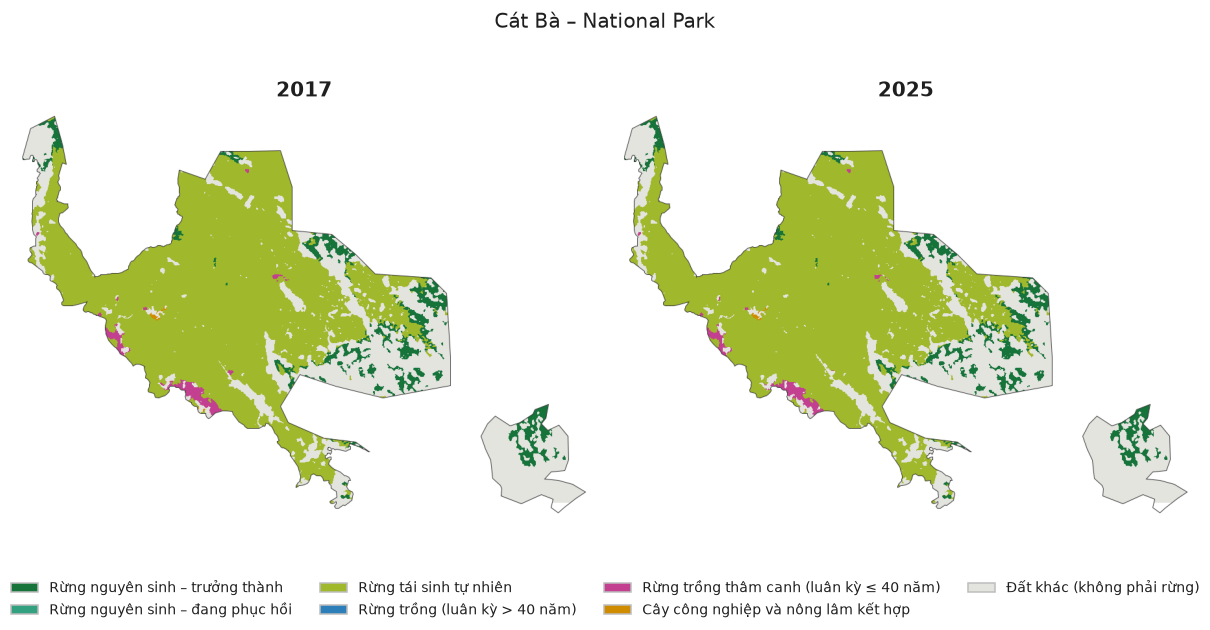

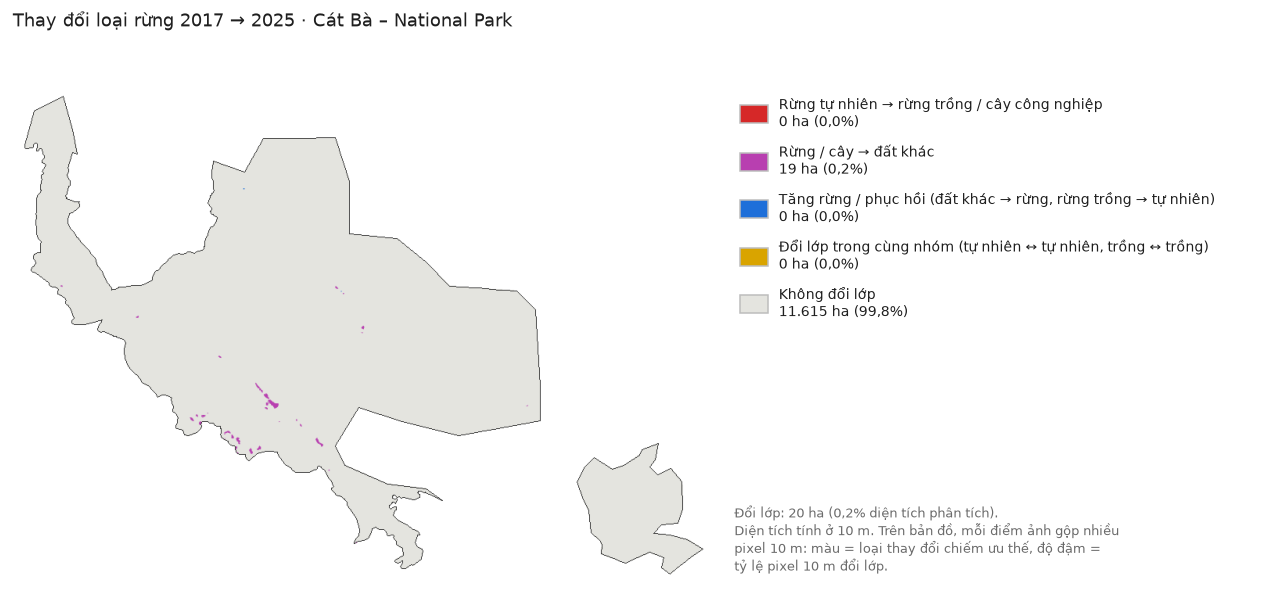

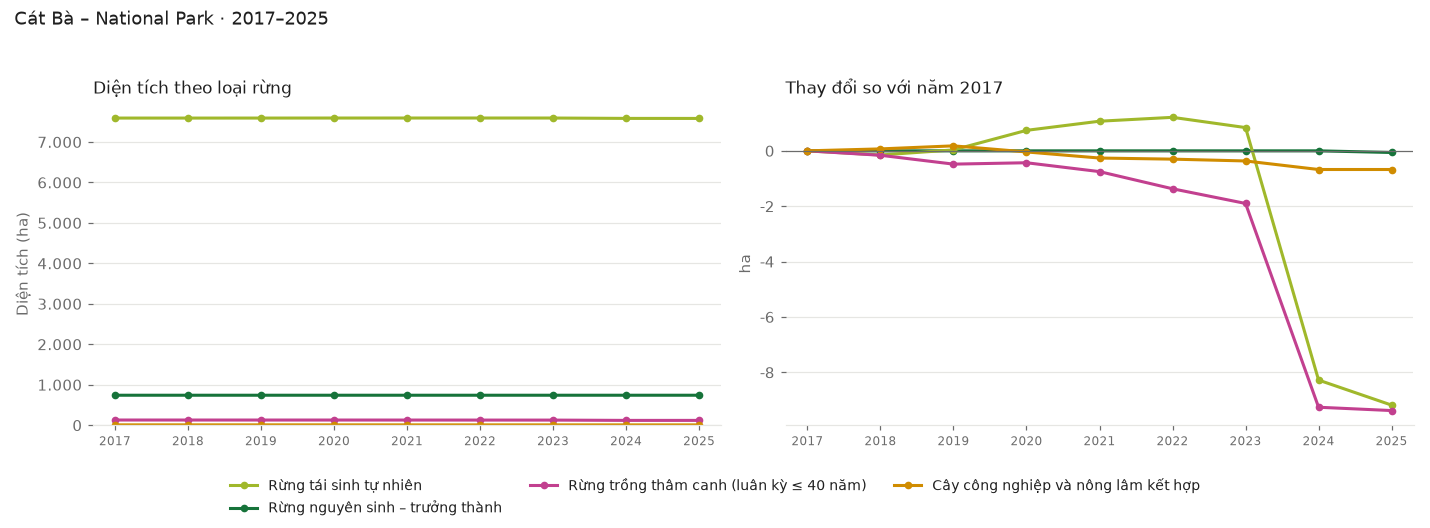

> **Nhận xét (AI, gemini-3.8-flash):** Giai đoạn 2017–2025, diện tích rừng tại Vườn quốc gia Cát Bà nhìn chung rất ổn định với tỷ lệ rừng tự nhiên duy trì quanh mức 71,6% đến 71,5%. Lớp rừng biến động nhiều nhất là rừng trồng thâm canh (giảm khoảng 9 ha, tương đương 7,3%) và rừng tái sinh tự nhiên (giảm khoảng 9 ha, tương đương 0,1%), trong khi rừng nguyên sinh giữ nguyên 741 ha. Xu hướng che phủ duy trì ổn định suốt từ năm 2017 đến 2023 ở mức 8.470 ha và chỉ giảm nhẹ từ năm 2024 xuống 8.451 ha. Mức giảm tập trung trong giai đoạn 2023–2024 cần được kiểm tra thực địa, dù có thể chỉ do sai số phân loại từ dữ liệu thử nghiệm.

### Cúc Phương (National Park, WDPA 7878)

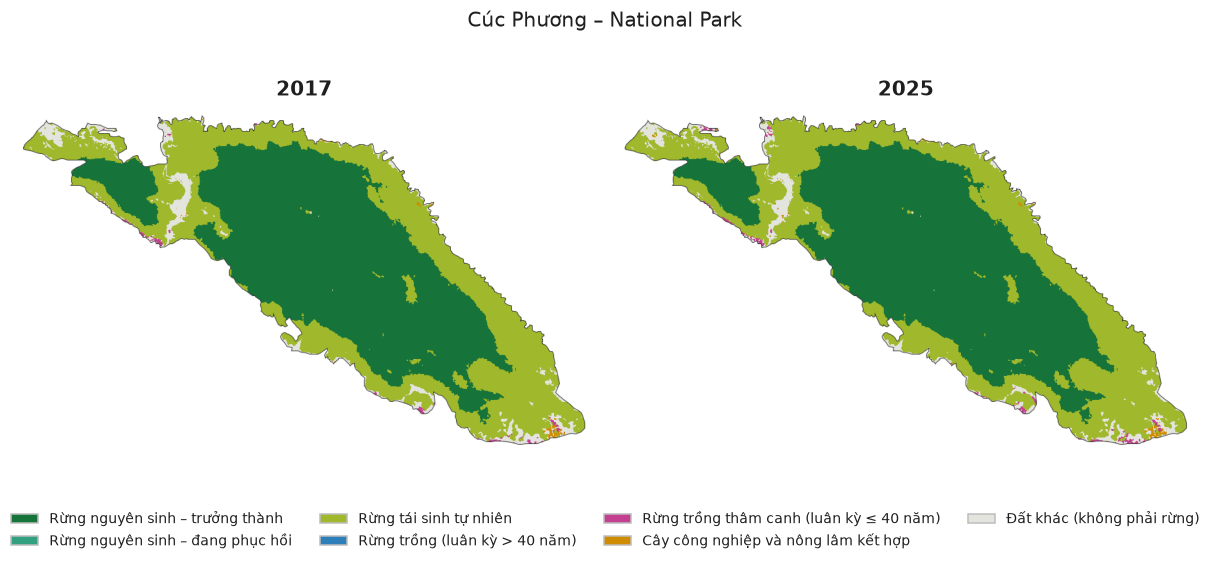

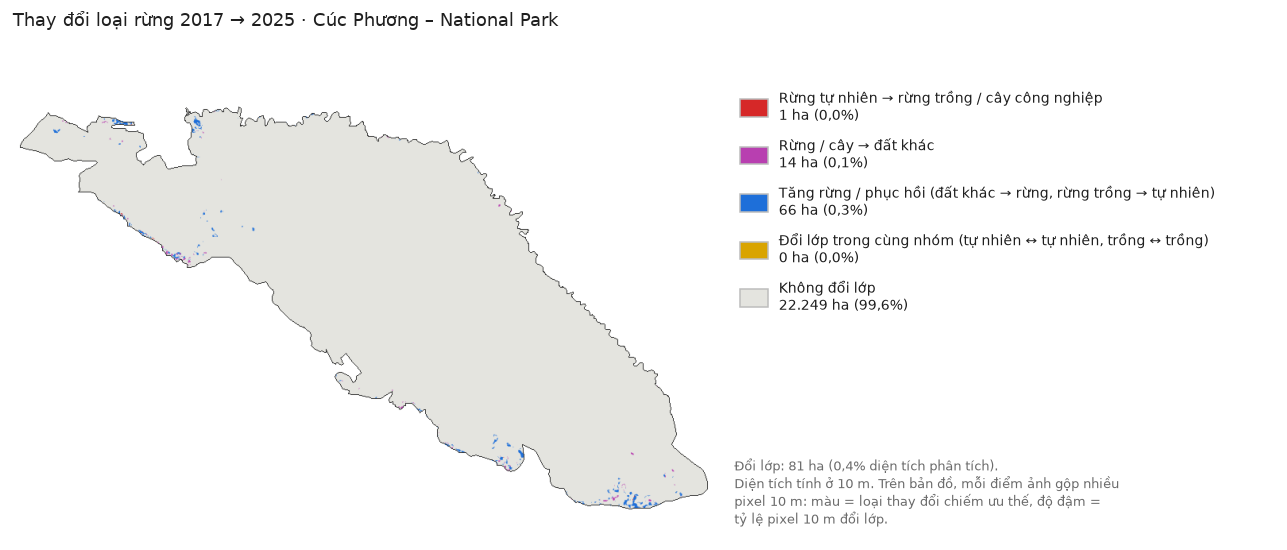

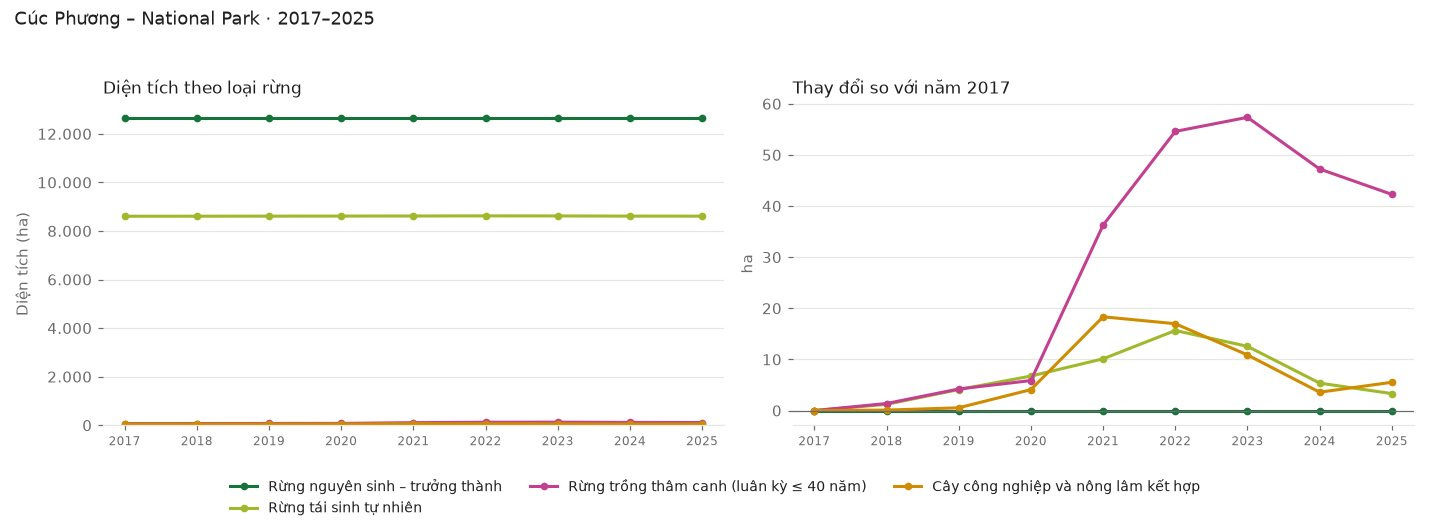

> **Nhận xét (AI, gemini-3.8-flash):** Giai đoạn 2017–2025, diện tích rừng tại Vườn quốc gia Cúc Phương nhìn chung rất ổn định với tỷ lệ rừng tự nhiên duy trì ở mức 95,2%, trong đó rừng nguyên sinh – trưởng thành giữ nguyên 12.653 ha. Lớp có biến động nhiều nhất là rừng trồng thâm canh khi tăng 42 ha (khoảng 61,5%), từ 69 ha năm 2017 lên 111 ha năm 2025. Xu hướng diện tích của lớp rừng này cùng cây công nghiệp có sự dao động rõ rệt, đạt đỉnh vào giai đoạn 2022–2023 trước khi giảm nhẹ trở lại. Do dữ liệu vệ tinh đang ở giai đoạn thử nghiệm, sự gia tăng của diện tích rừng trồng cần được kiểm tra thực địa vì chênh lệch này cũng có thể do nhiễu phân loại.

### Bạch Mã (National Park, WDPA 10110)

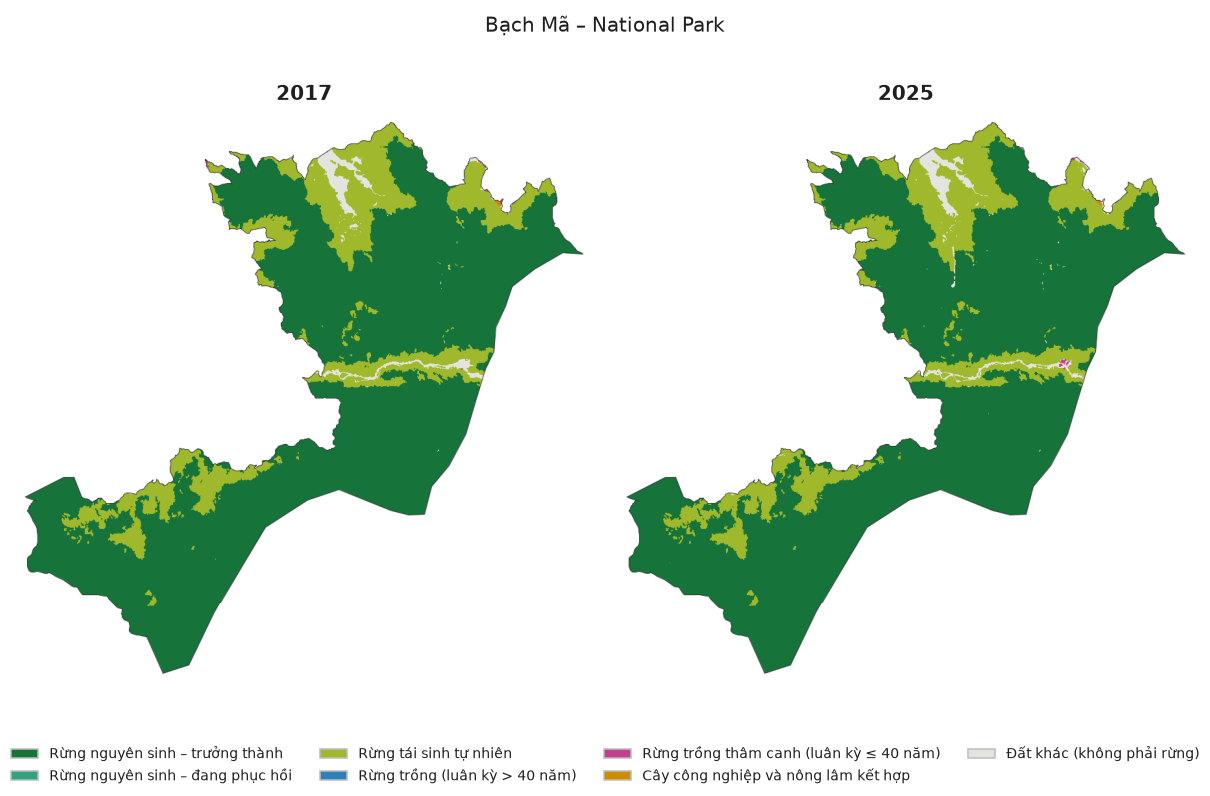

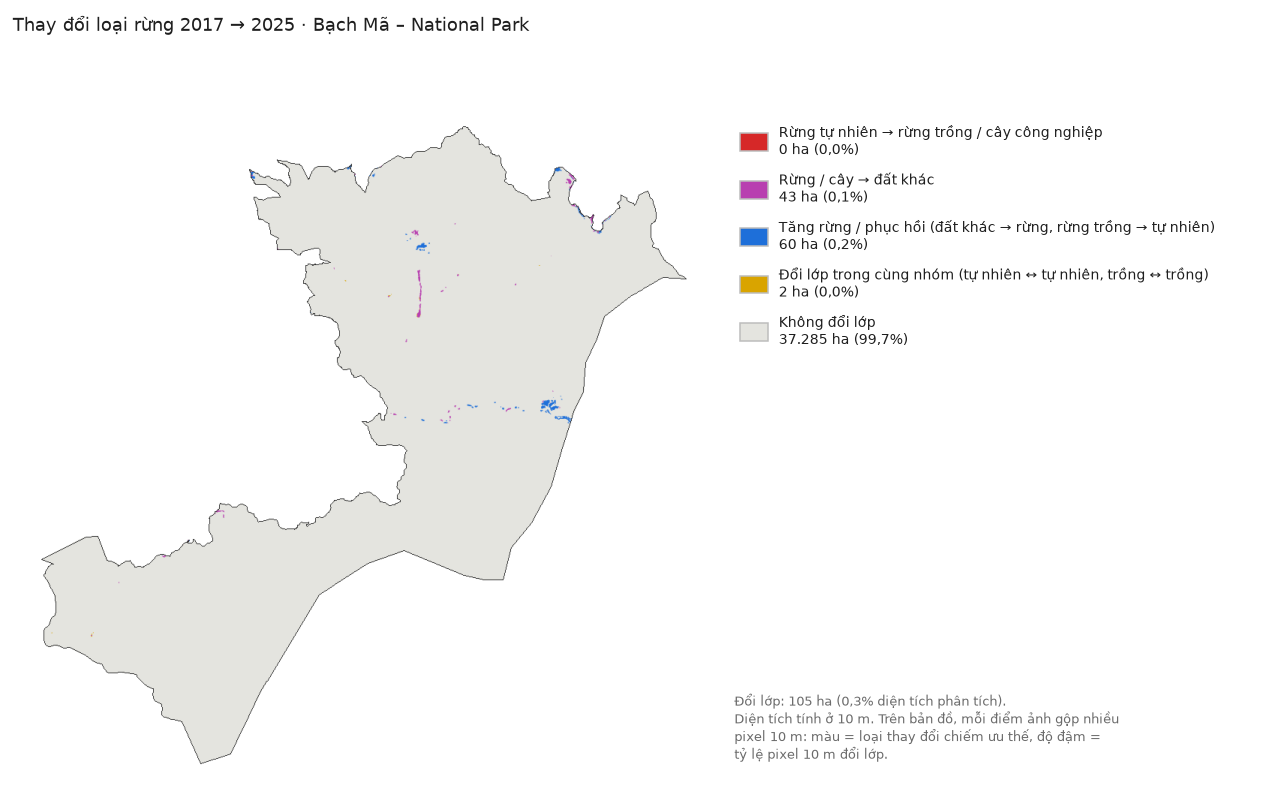

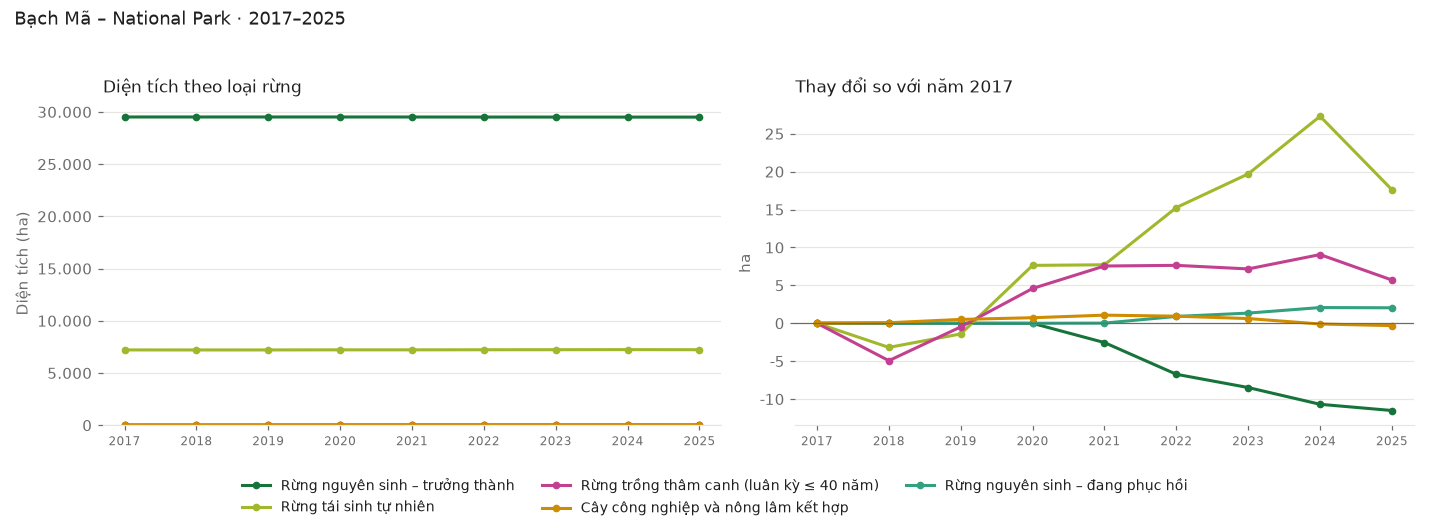

> **Nhận xét (AI, gemini-3.8-flash):** Giai đoạn 2017–2025, diện tích rừng và cây tại Vườn quốc gia Bạch Mã duy trì rất ổn định quanh mức 36.770 ha, trong đó tỷ lệ rừng tự nhiên luôn chiếm ưu thế vượt trội khi tăng nhẹ từ 98,2% lên 98,3%. Về quy mô biến động, rừng tái sinh tự nhiên tăng nhiều nhất về diện tích với 18 ha (tăng 0,2%), trong khi rừng trồng thâm canh có mức tăng tương đối lớn nhất với 6 ha (tăng 29,0%). Diện tích rừng nguyên sinh trưởng thành giữ nguyên giai đoạn đầu nhưng có xu hướng giảm nhẹ đều từ năm 2021 đến 2025 với tổng mức giảm 12 ha. Dù chênh lệch nhỏ này có thể do nhiễu phân loại của ảnh vệ tinh, khu bảo tồn vẫn cần kiểm tra thực địa tại các khu vực rừng nguyên sinh biến động để xác định diễn biến thực tế.

### Côn Đảo (National Park, WDPA 10111)

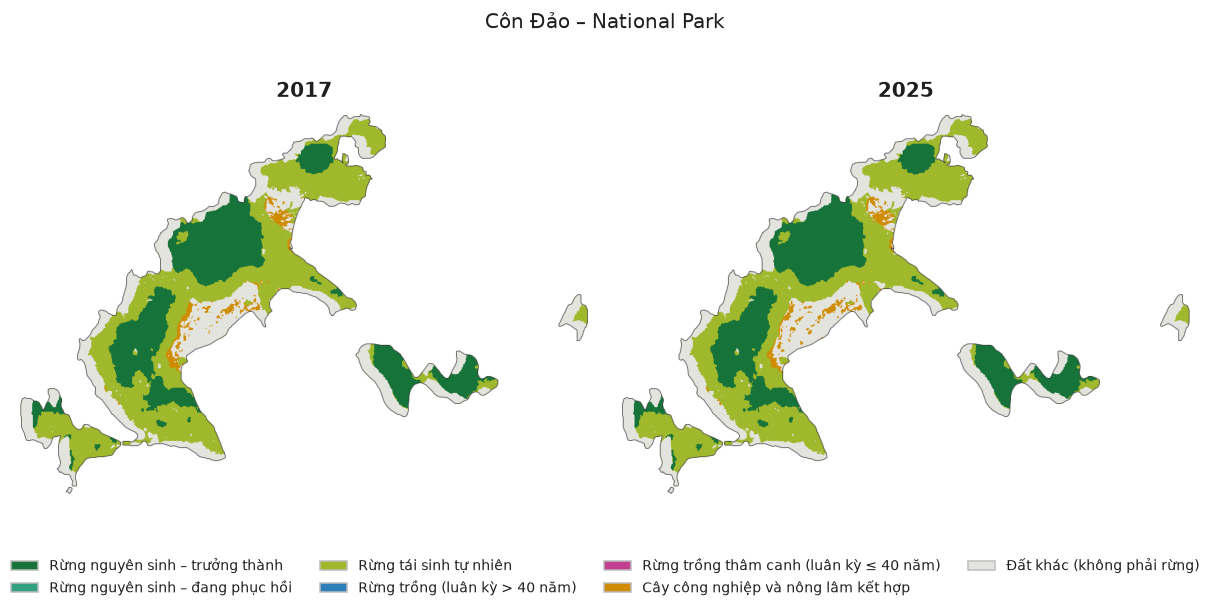

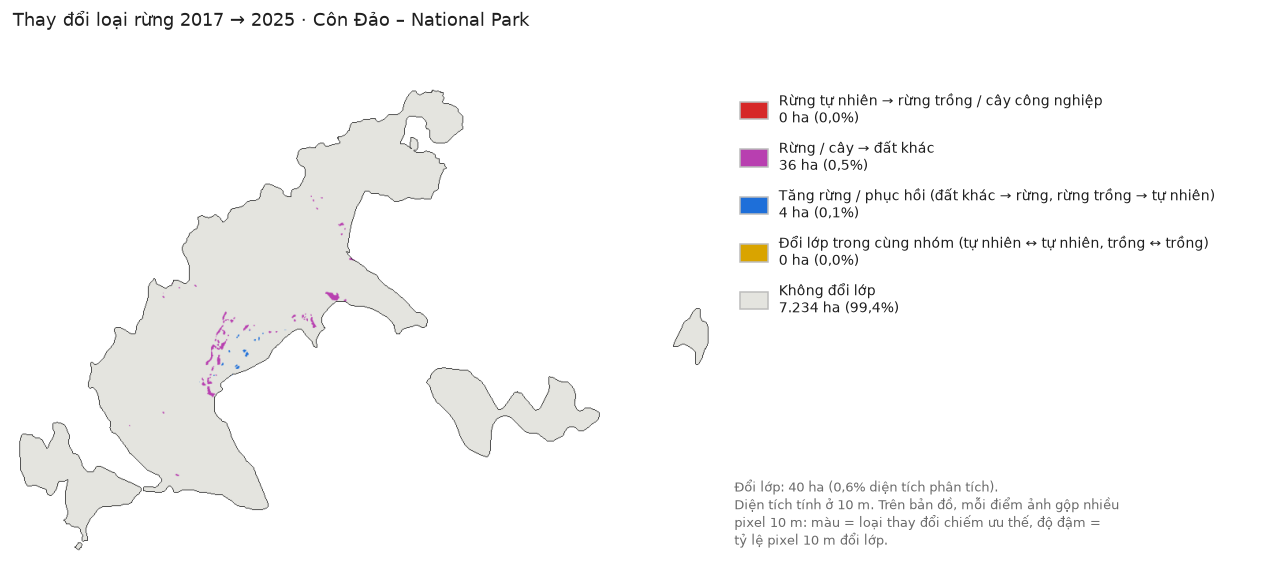

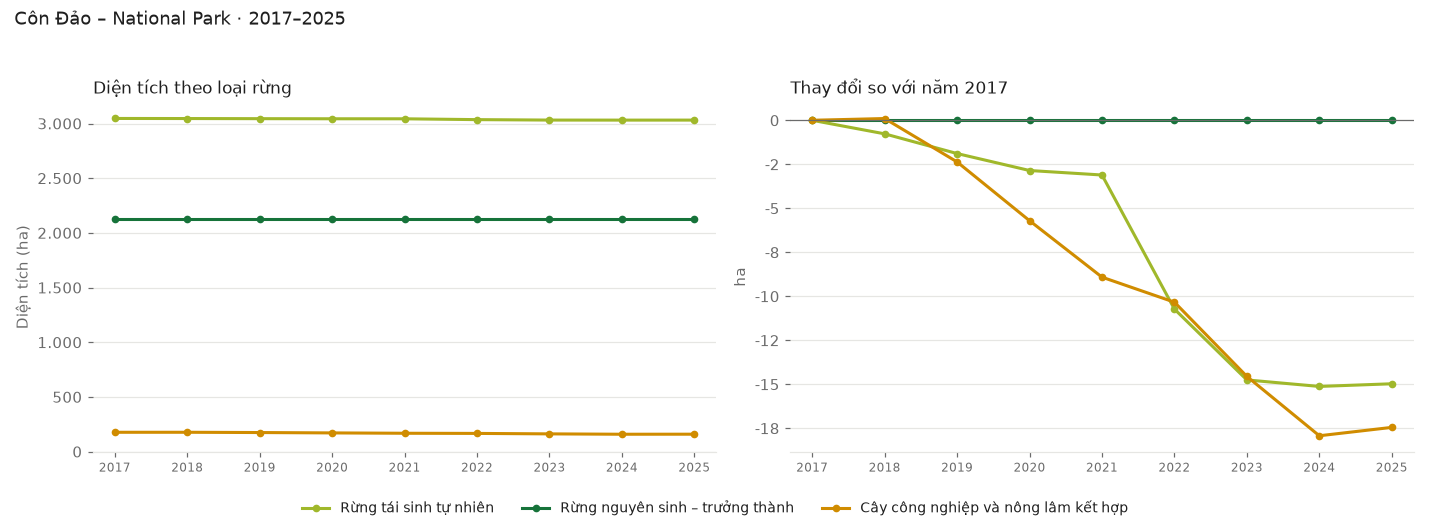

> **Nhận xét (AI, gemini-3.8-flash):** Giai đoạn 2017–2025, diện tích rừng và cây tại Vườn quốc gia Côn Đảo nhìn chung ổn định với tỷ lệ che phủ rừng tự nhiên duy trì ở mức cao, từ 71,1% giảm nhẹ còn 70,9%. Trong khi rừng nguyên sinh – trưởng thành giữ nguyên 2.127 ha, lớp cây công nghiệp và nông lâm kết hợp biến động mạnh nhất khi giảm 9,9% (khoảng 17 ha), tiếp theo là rừng tái sinh tự nhiên giảm 15 ha (khoảng 0,5%). Tổng diện tích rừng và cây có xu hướng giảm nhẹ và đều đặn từ 5.350 ha xuống 5.317 ha, đi kèm diện tích đất khác tăng 33 ha. Mức chênh lệch nhỏ này có thể do chuyển đổi thực tế hoặc do nhiễu phân loại ảnh vệ tinh, vì vậy cần kiểm tra thực địa tại các vị trí biến động.

### Vườn quốc gia Ba Vì (National Park, WDPA 10113)

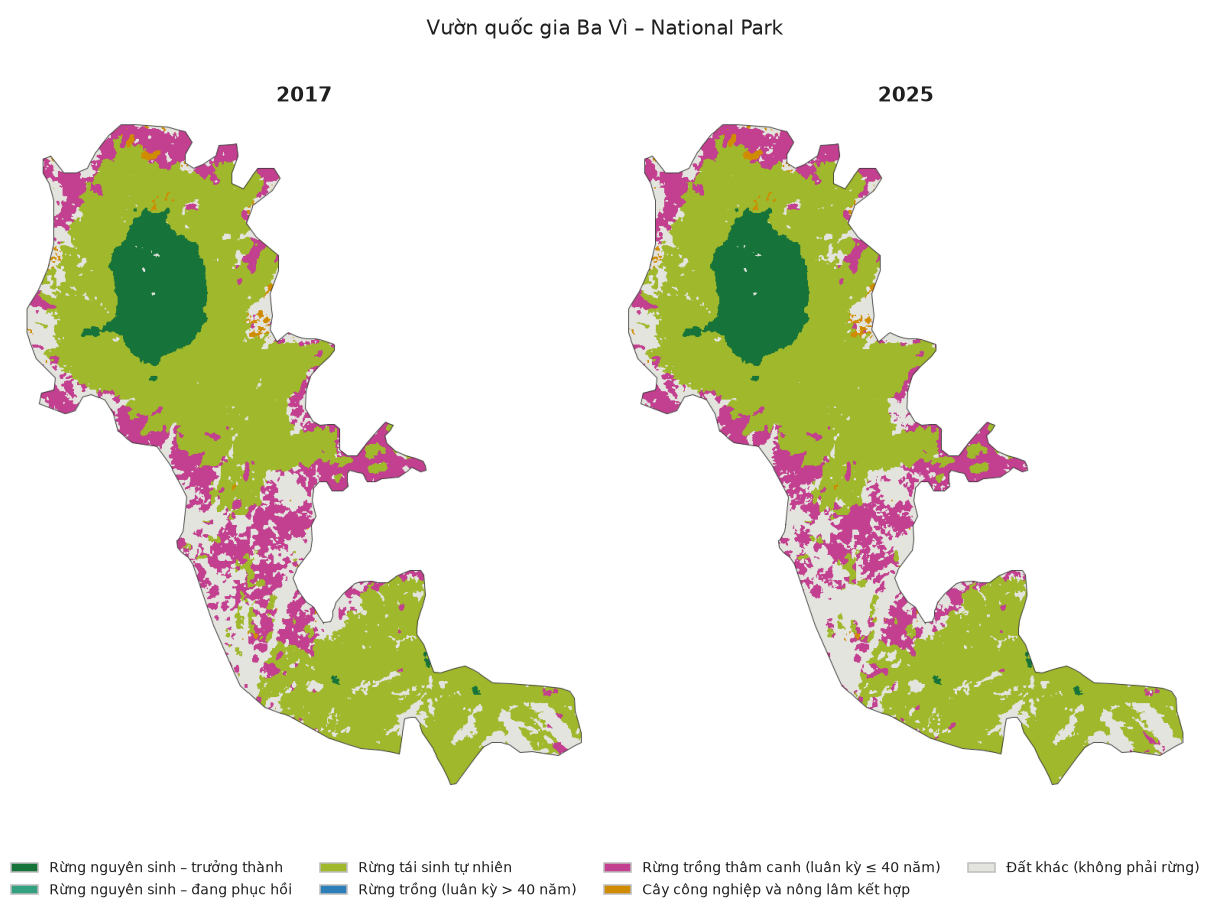

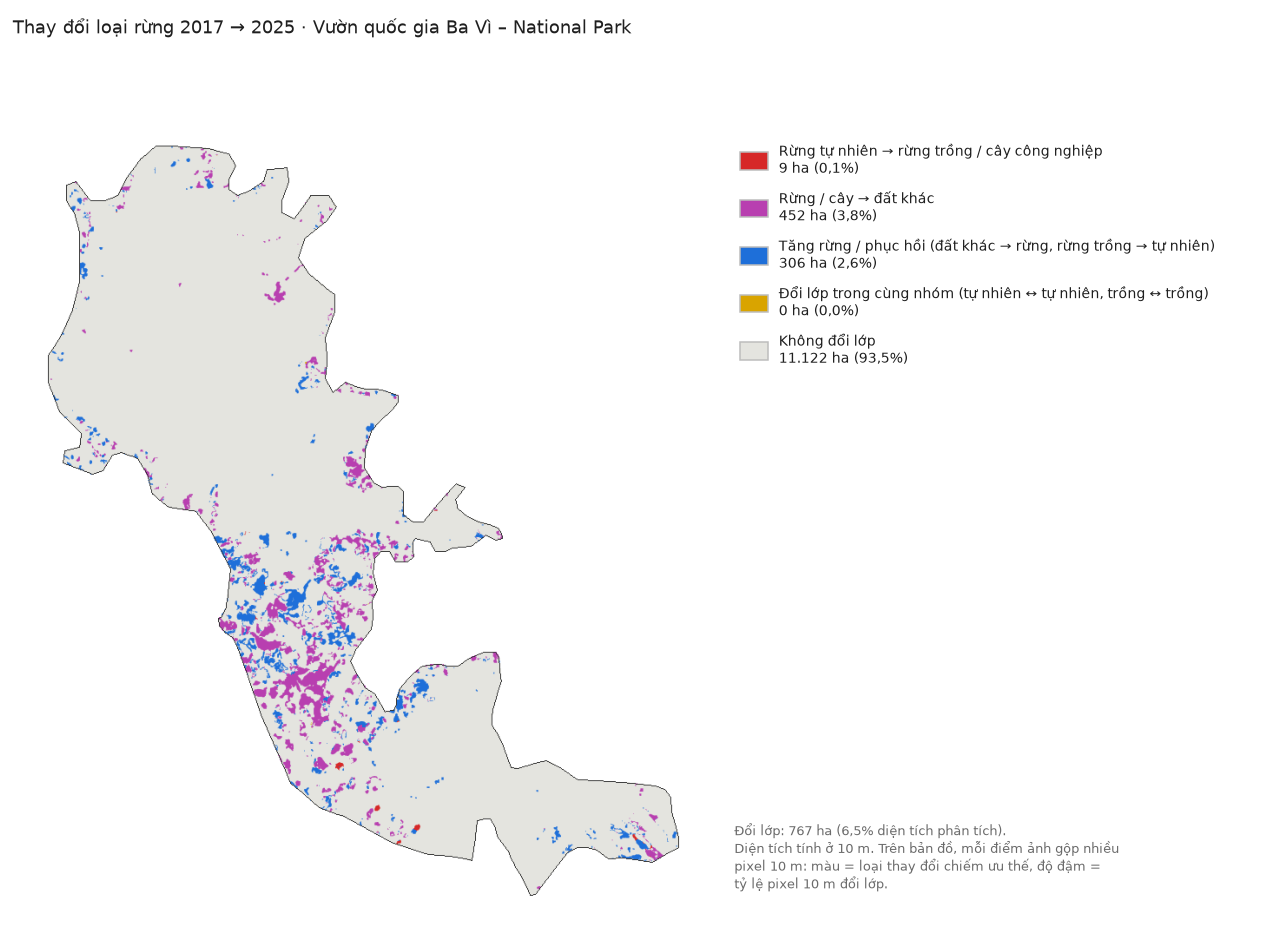

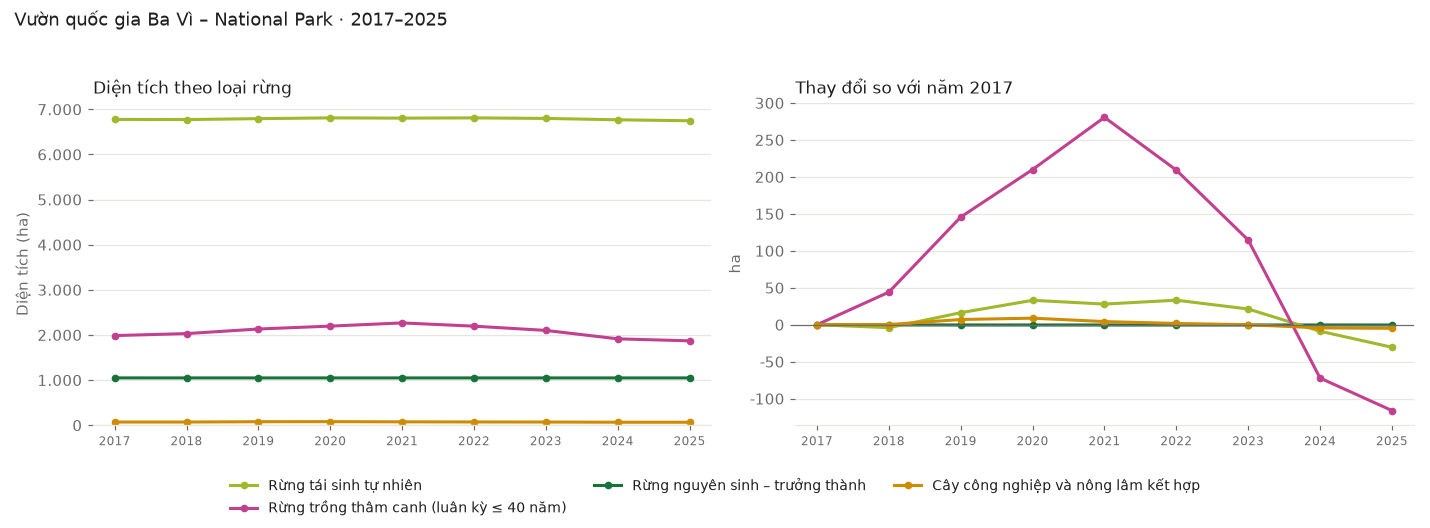

> **Nhận xét (AI, gemini-3.8-flash):** Giai đoạn 2017–2025, tổng diện tích rừng và cây tại Vườn quốc gia Ba Vì dao động rõ rệt, tăng từ 9.882 ha lên mức cao nhất 10.195 ha năm 2021 rồi giảm về 9.731 ha, song tỷ lệ rừng tự nhiên vẫn giữ ổn định quanh 65,6% đến 65,8%. Rừng trồng thâm canh là lớp thay đổi nhiều nhất khi giảm 116 ha (khoảng 5,8%), ghi nhận xu hướng tăng liên tục nửa đầu kỳ rồi sụt giảm nhanh về sau. Diện tích rừng nguyên sinh duy trì ổn định ở mức 1.048 ha, trong khi mức giảm 30 ha (khoảng 0,4%) ở rừng tái sinh tự nhiên có thể do sai số phân loại thử nghiệm. Đáng chú ý, diện tích đất không phải rừng tăng thêm 152 ha cần được kiểm tra thực địa để xác định khả năng do hoạt động khai thác luân kỳ của rừng trồng.

### Ngoc Trao (Cultural and Historical Site, WDPA 10114)

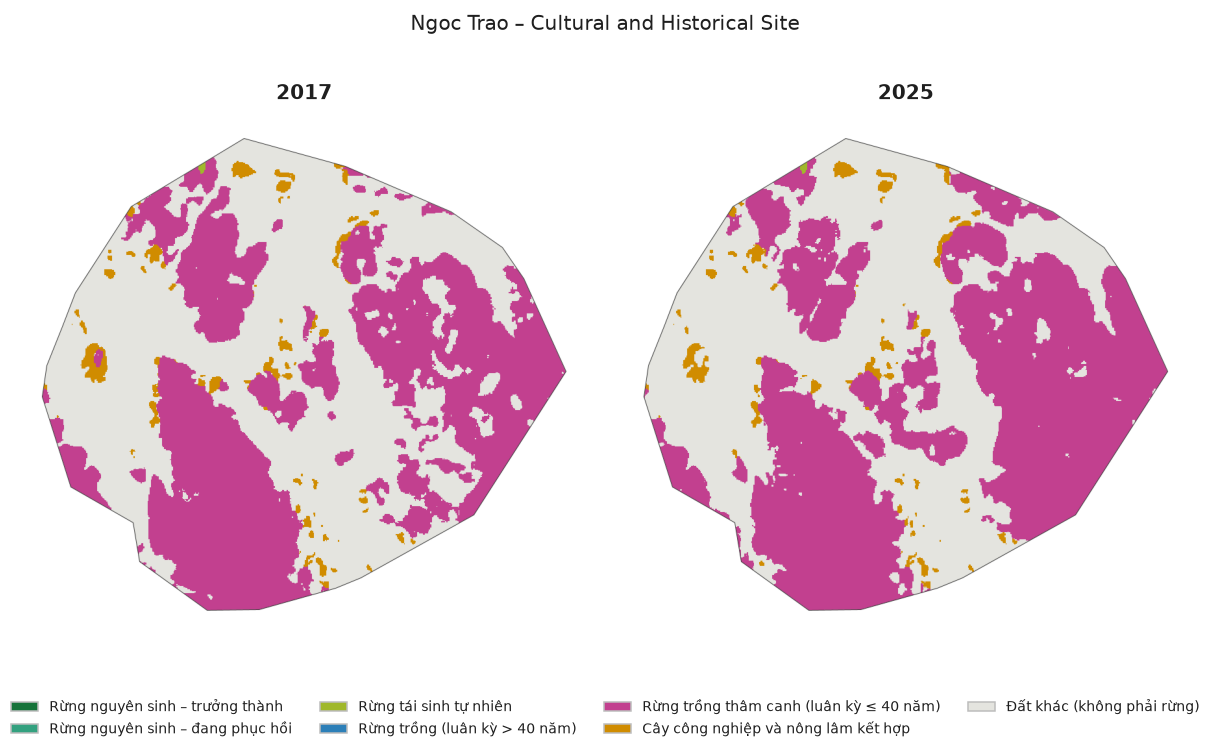

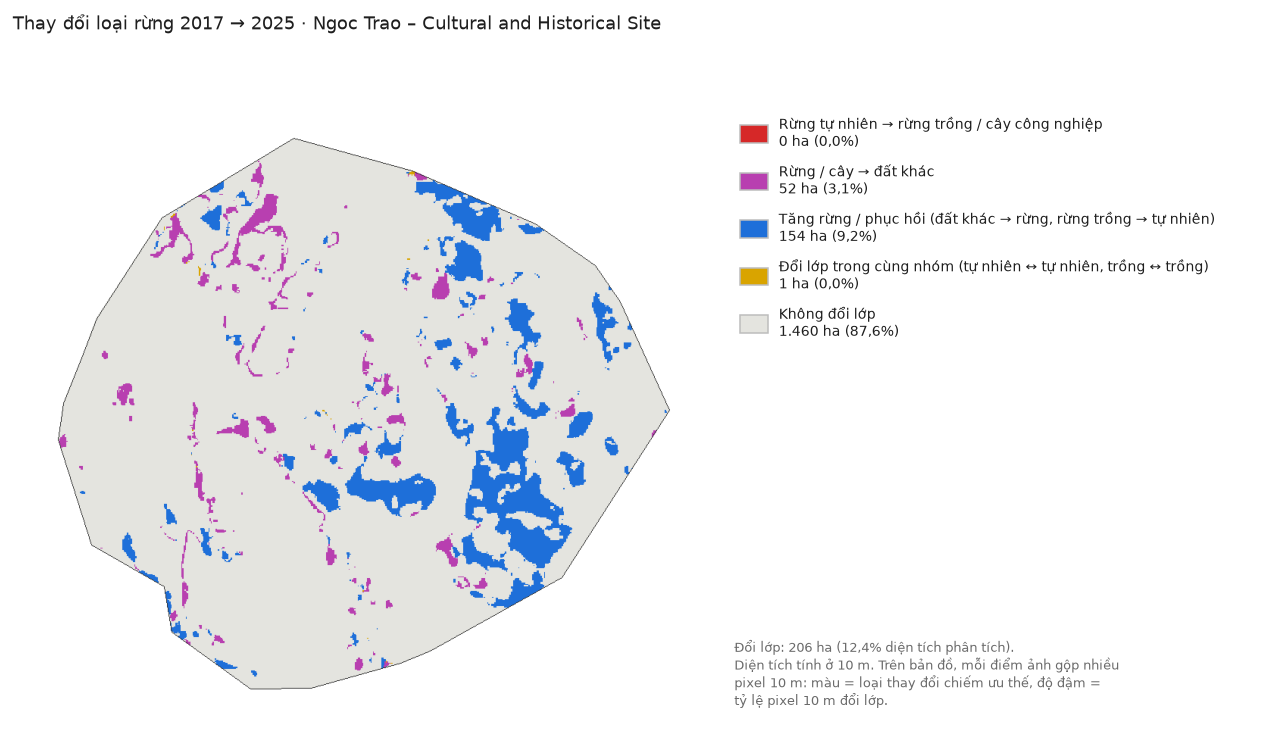

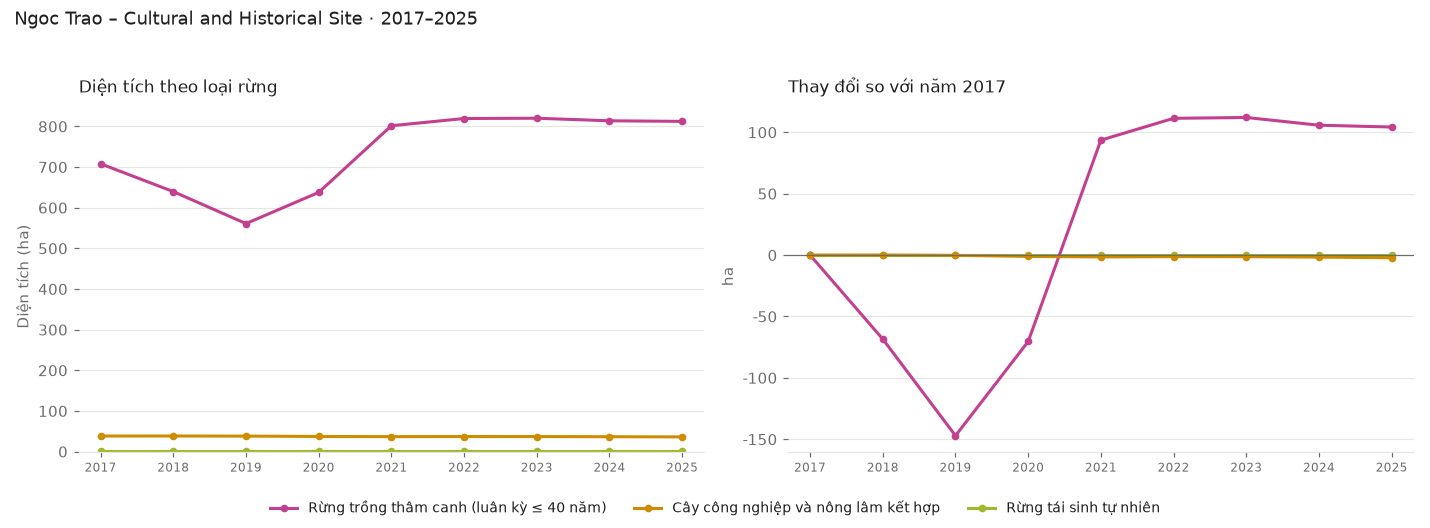

> **Nhận xét (AI, gemini-3.8-flash):** Giai đoạn 2017–2025, tổng diện tích rừng và cây tại khu vực tăng từ 747 ha lên 849 ha, trong khi tỷ lệ rừng tự nhiên duy trì ở mức 0,0% do diện tích rừng tái sinh chỉ chiếm 1 ha. Lớp có biến động nhiều nhất là rừng trồng thâm canh với mức tăng 104 ha (khoảng 14,7%), còn cây công nghiệp và nông lâm kết hợp giảm 2 ha (5,7%). Xu hướng che phủ không tăng đều mà dao động mạnh, giảm sâu xuống 600 ha vào năm 2019 trước khi phục hồi và duy trì ổn định quanh mức 850 ha từ năm 2022. Sự thay đổi lớn của rừng trồng thâm canh có thể do chu kỳ khai thác luân canh, song cũng cần kiểm tra thực địa để loại trừ sai số phân loại từ dữ liệu viễn thám thử nghiệm.

### Đền Hùng (Cultural and Historical Site, WDPA 10117)

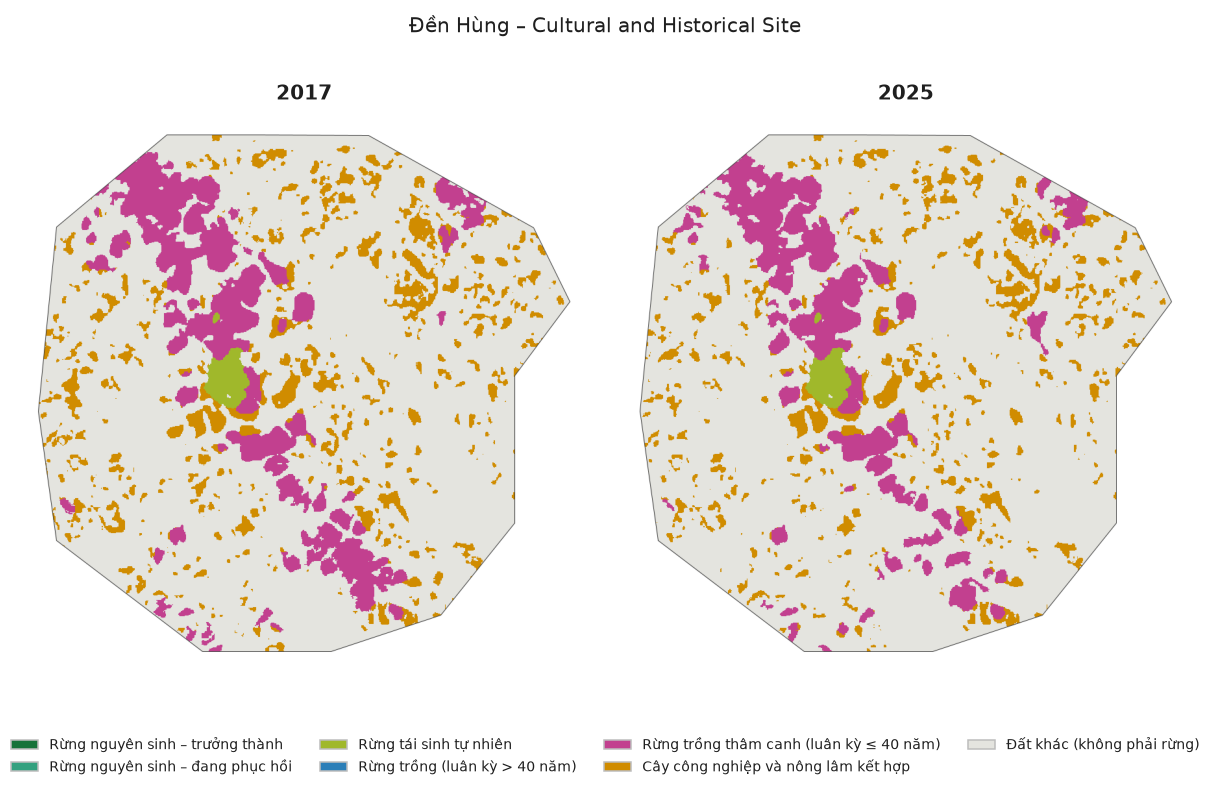

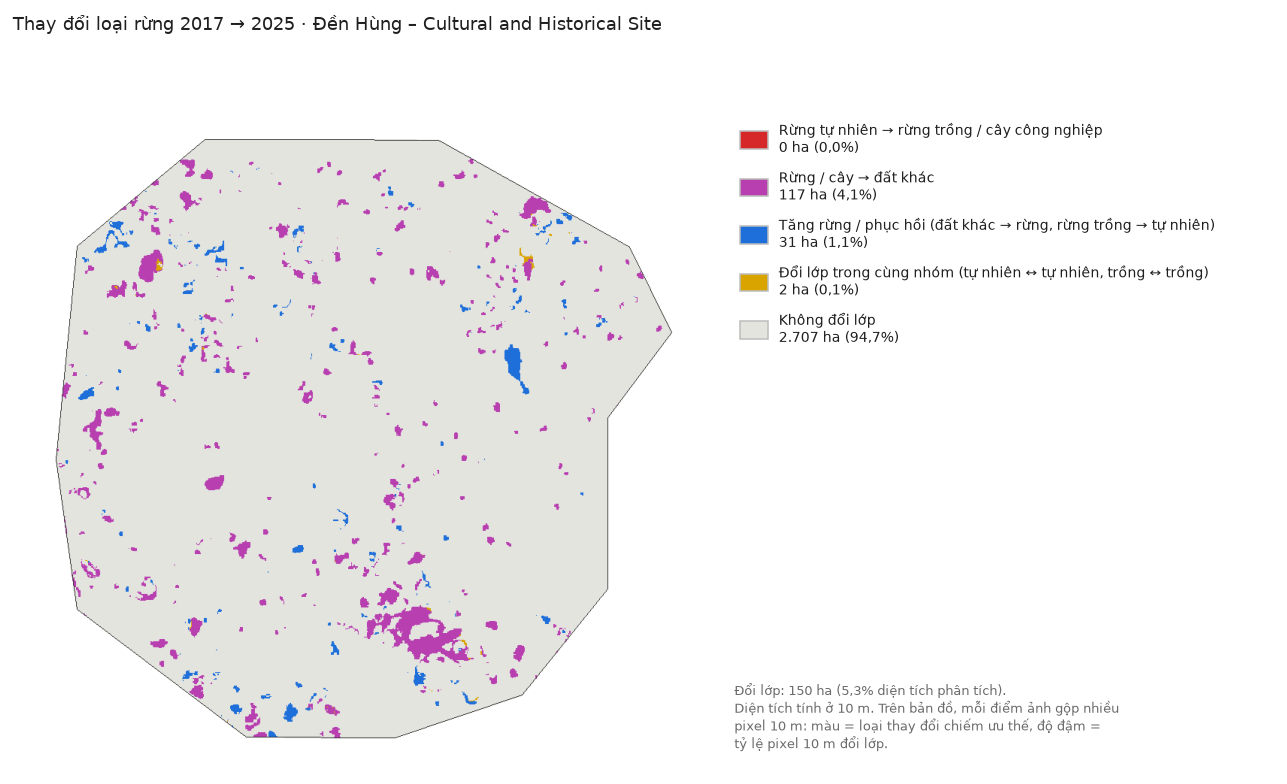

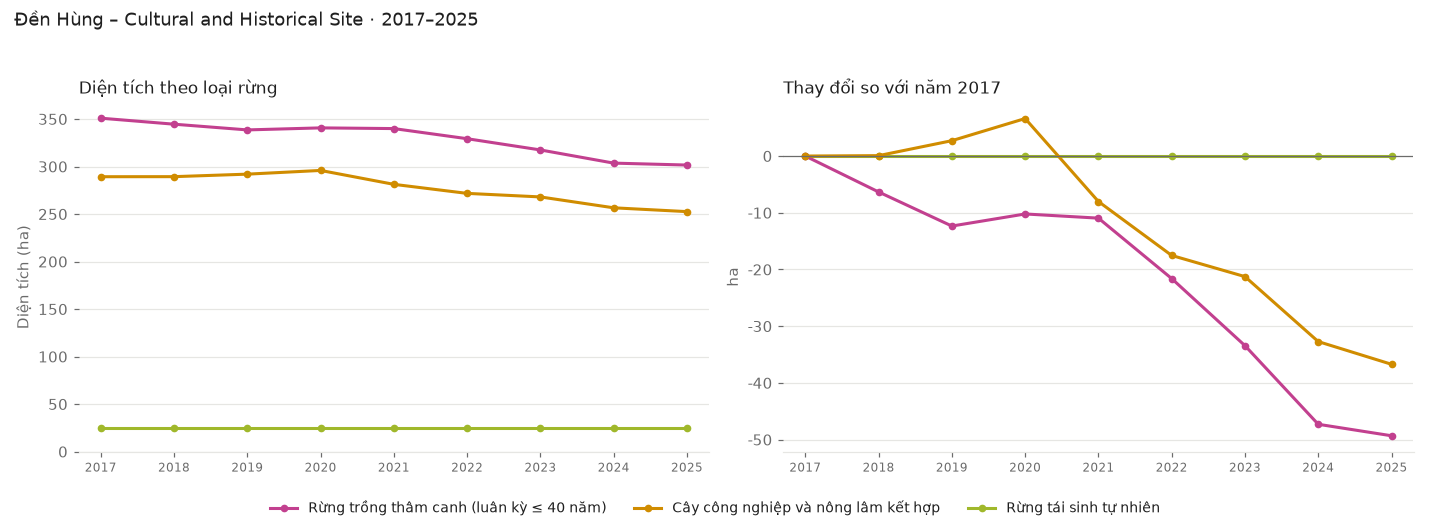

> **Nhận xét (AI, gemini-3.8-flash):** Giai đoạn 2017–2025, tổng diện tích rừng và cây tại Đền Hùng giảm từ 665 ha xuống 579 ha, trong khi tỷ lệ rừng tự nhiên duy trì ổn định ở mức 0,9% với 25 ha rừng tái sinh. Biến động giảm rõ rệt nhất diễn ra ở rừng trồng thâm canh với mức giảm 49 ha (giảm 14,1%) và cây công nghiệp, nông lâm kết hợp giảm 37 ha (giảm 12,7%). Tổng diện tích che phủ thể hiện xu hướng giảm tương đối đều và liên tục từ sau năm 2020, đi cùng sự gia tăng của đất khác từ 2.192 ha lên 2.278 ha. Mức suy giảm này có thể do hoạt động khai thác theo chu kỳ luân canh hoặc chuyển đổi mục đích sử dụng đất, cần được xác minh thêm qua kiểm tra thực địa.

### Bắc Sơn (Nature Reserve, WDPA 10127)

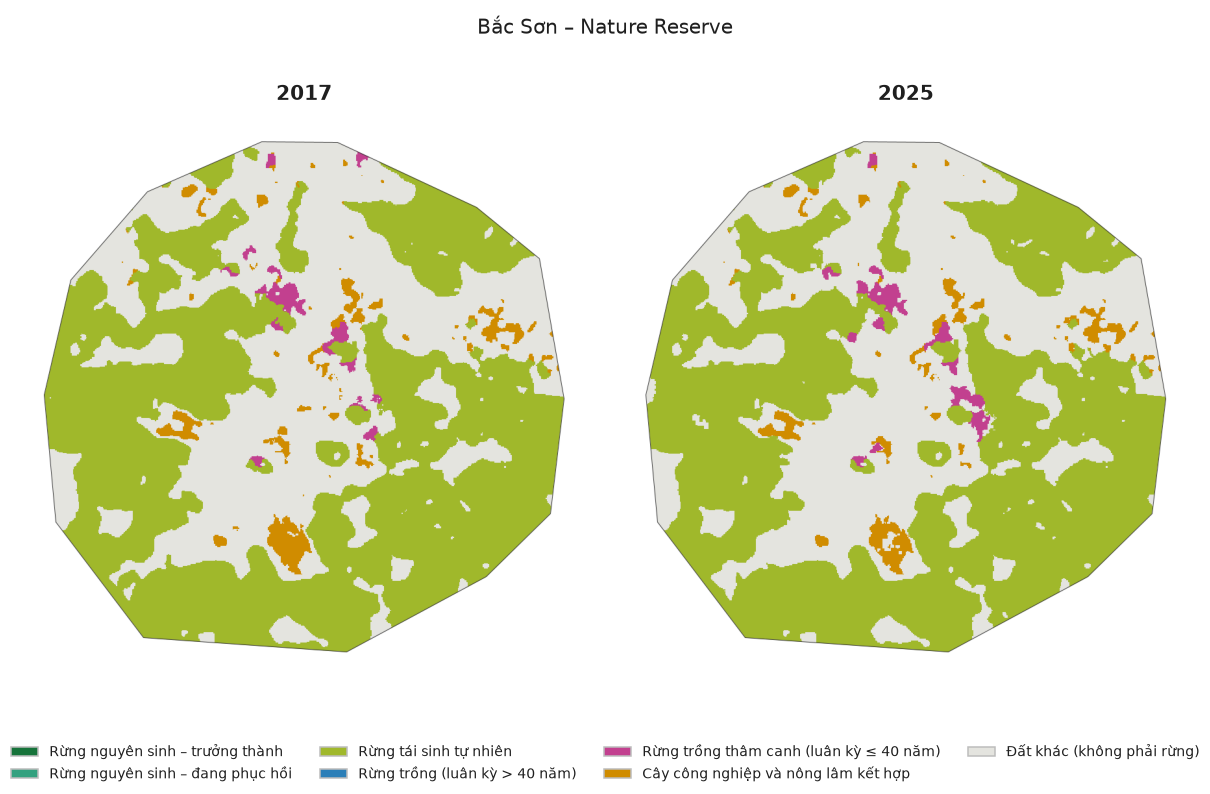

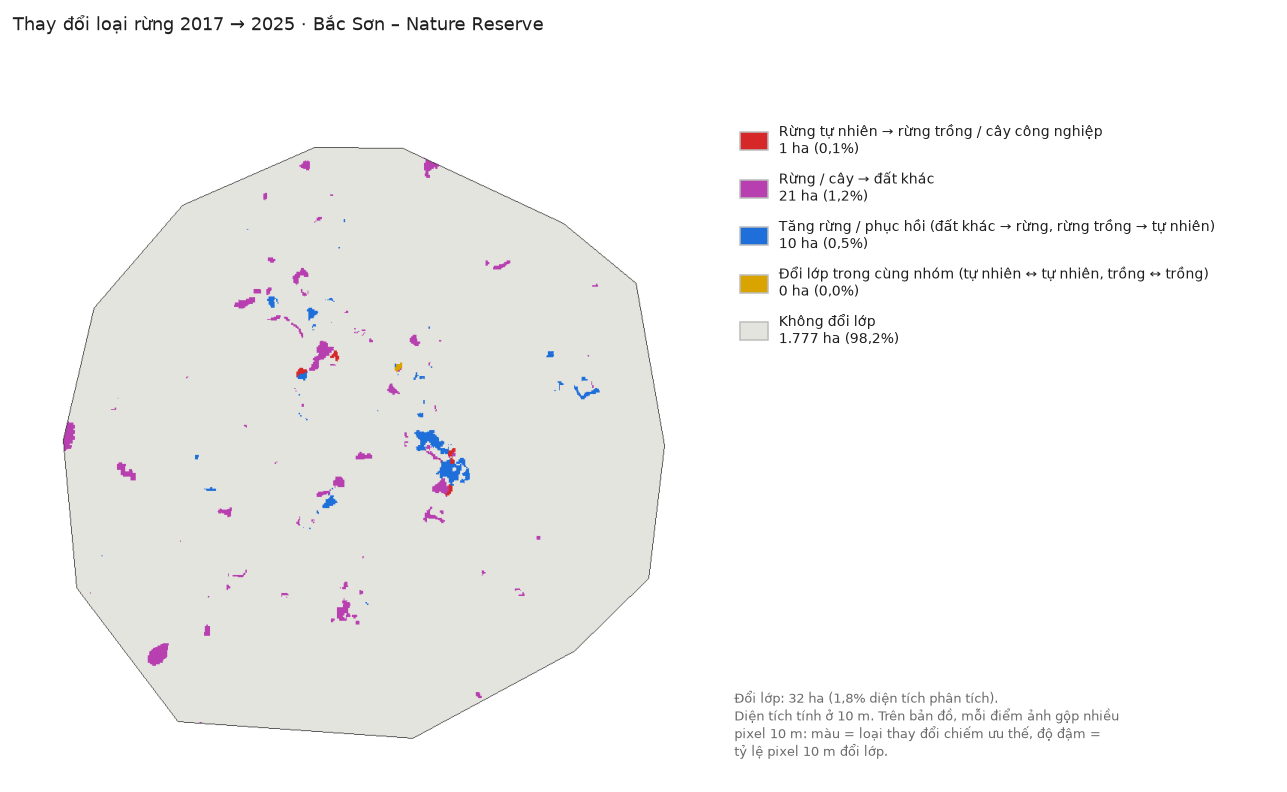

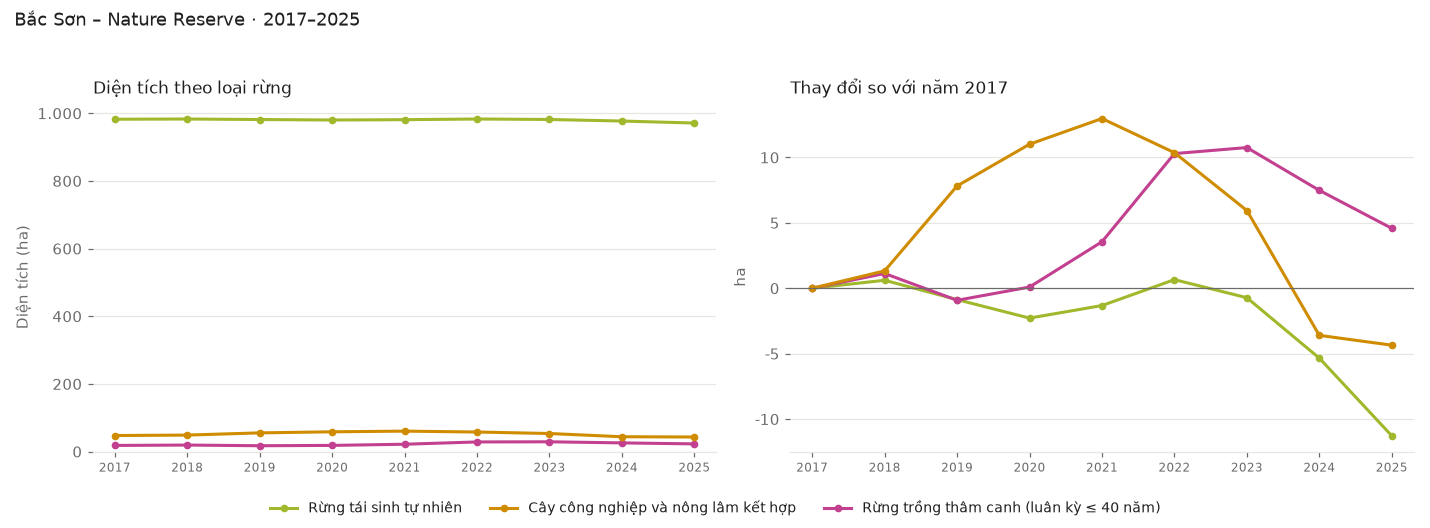

> **Nhận xét (AI, gemini-3.8-flash):** Giai đoạn 2017–2025, diện tích rừng và cây tại Khu bảo tồn Bắc Sơn biến động nhẹ theo xu hướng tăng đến năm 2022 rồi giảm xuống 1.037 ha vào năm 2025, trong khi tỷ lệ rừng tự nhiên duy trì ổn định từ 54,3% giảm nhẹ xuống 53,7%. Rừng tái sinh tự nhiên giảm diện tích tuyệt đối nhiều nhất với 11 ha (giảm 1,1%), còn rừng trồng thâm canh biến động tỷ lệ lớn nhất khi tăng 25,0% (tăng 5 ha). Xu hướng chung diễn ra dao động qua các năm chứ không tăng giảm đều đặn. Do dữ liệu mang tính thử nghiệm, mức giảm 12 ha của rừng tái sinh tự nhiên từ năm 2022 đến 2025 cần được kiểm tra thực địa để xác định là suy thoái rừng hay chỉ do nhiễu phân loại.

### Bán đảo Sơn Trà (Nature Reserve, WDPA 10187)

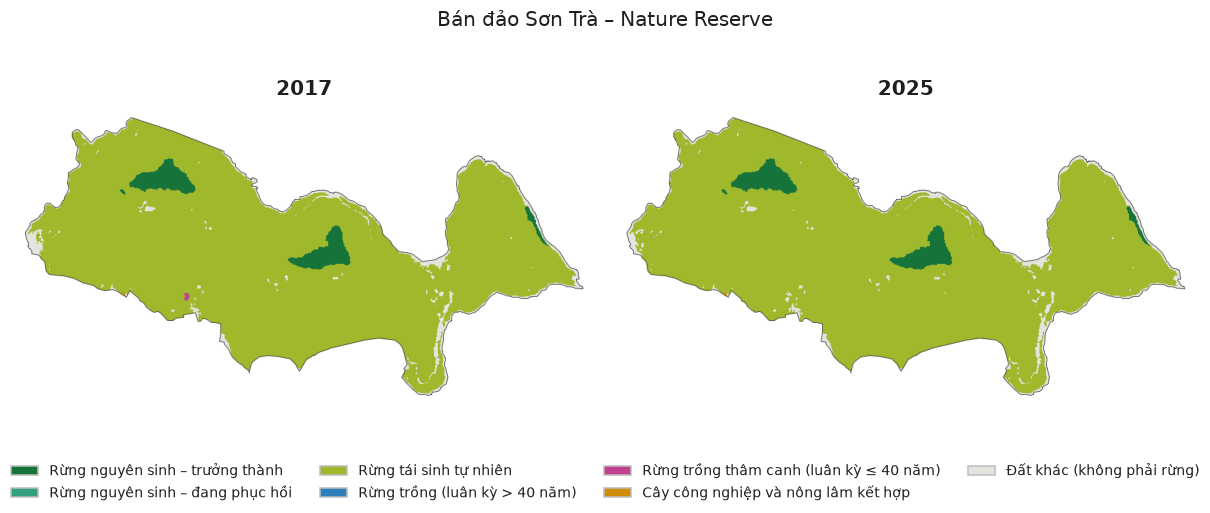

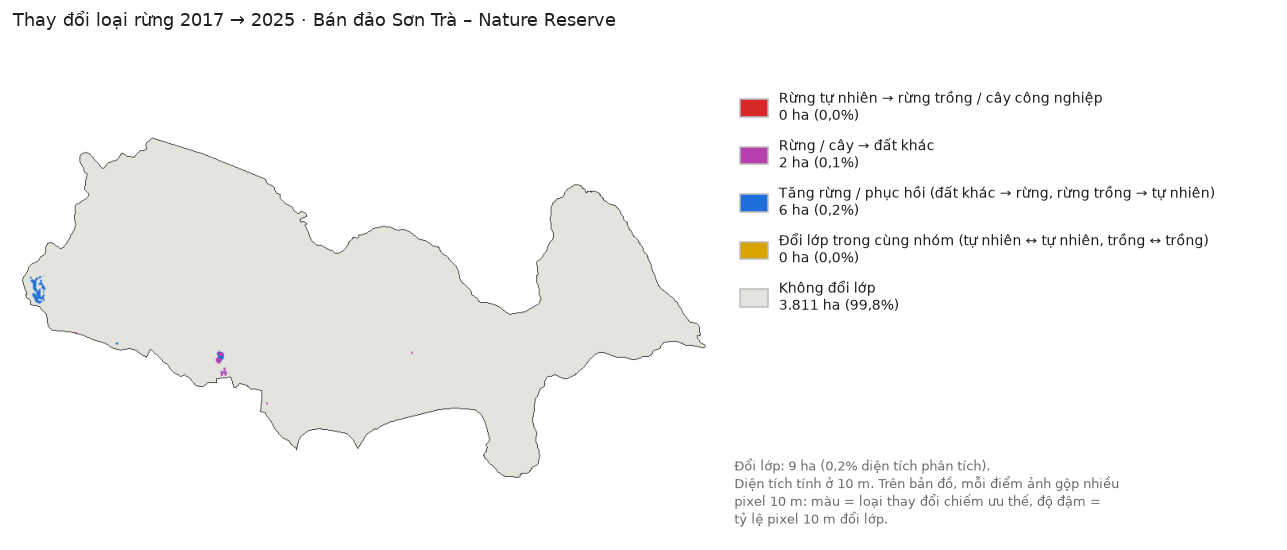

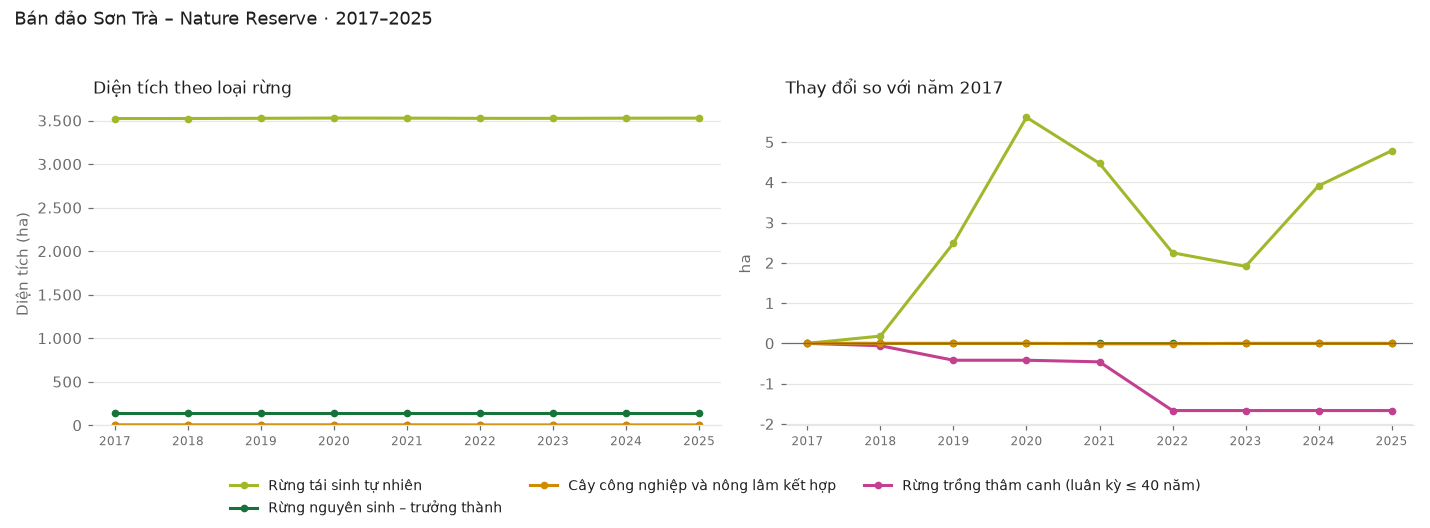

> **Nhận xét (AI, gemini-3.8-flash):** Giai đoạn 2017–2025, độ che phủ rừng tại Bán đảo Sơn Trà duy trì rất ổn định với tỷ lệ rừng tự nhiên chiếm ưu thế vượt trội, tăng nhẹ từ 95,8% lên 95,9%. Về quy mô biến động, rừng tái sinh tự nhiên tăng 5 ha (0,1%), trong khi rừng trồng thâm canh giảm mạnh nhất về tỷ lệ với mức giảm 2 ha (-100,0%) và rừng nguyên sinh giữ nguyên ở mức 135 ha. Nhìn chung, tổng diện tích rừng và cây phân bố đều và chỉ dao động nhỏ trong biên độ hẹp từ 3.661 ha đến 3.666 ha. Do mức chênh lệch rất nhỏ này có thể do nhiễu phân loại từ bản đồ vệ tinh ForTy V2 Beta, ban quản lý cần kiểm tra thực địa tại các vị trí từng có rừng trồng để xác định chính xác thực trạng phục hồi.

### Vườn quốc gia Ba Bể (National Park, WDPA 10188)

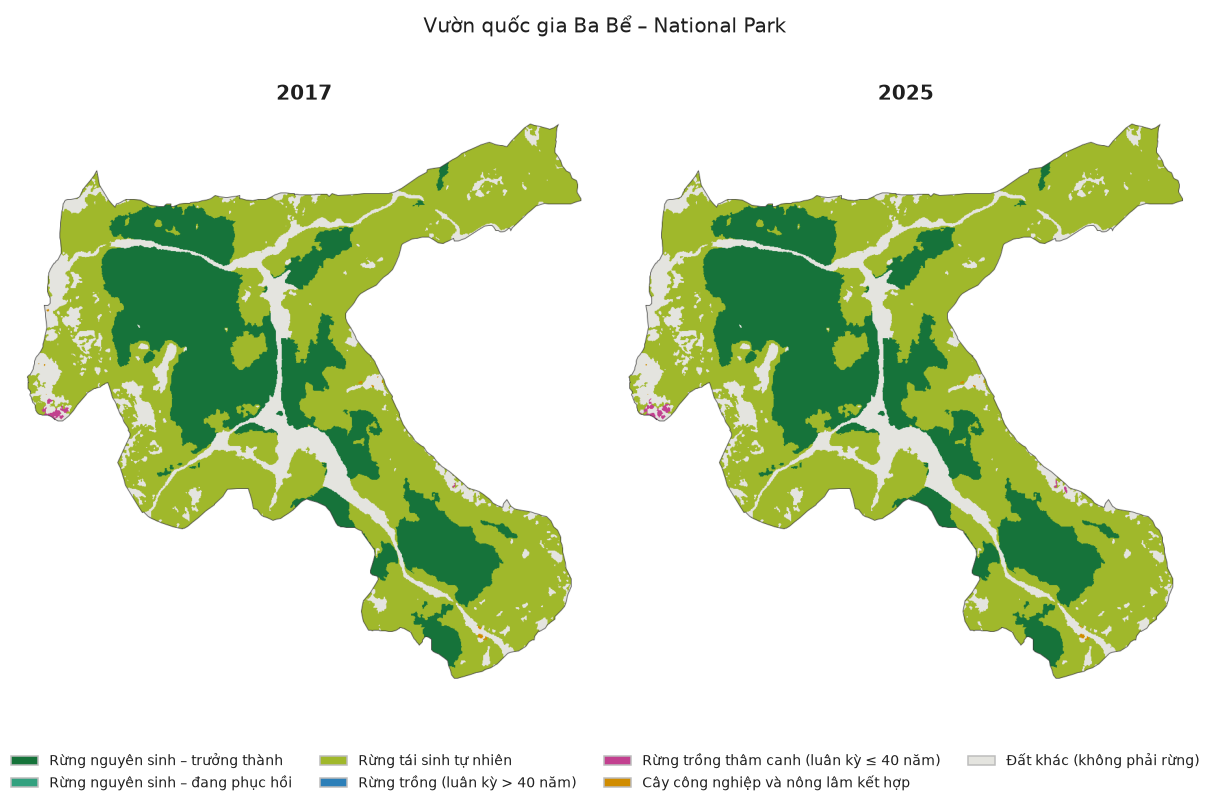

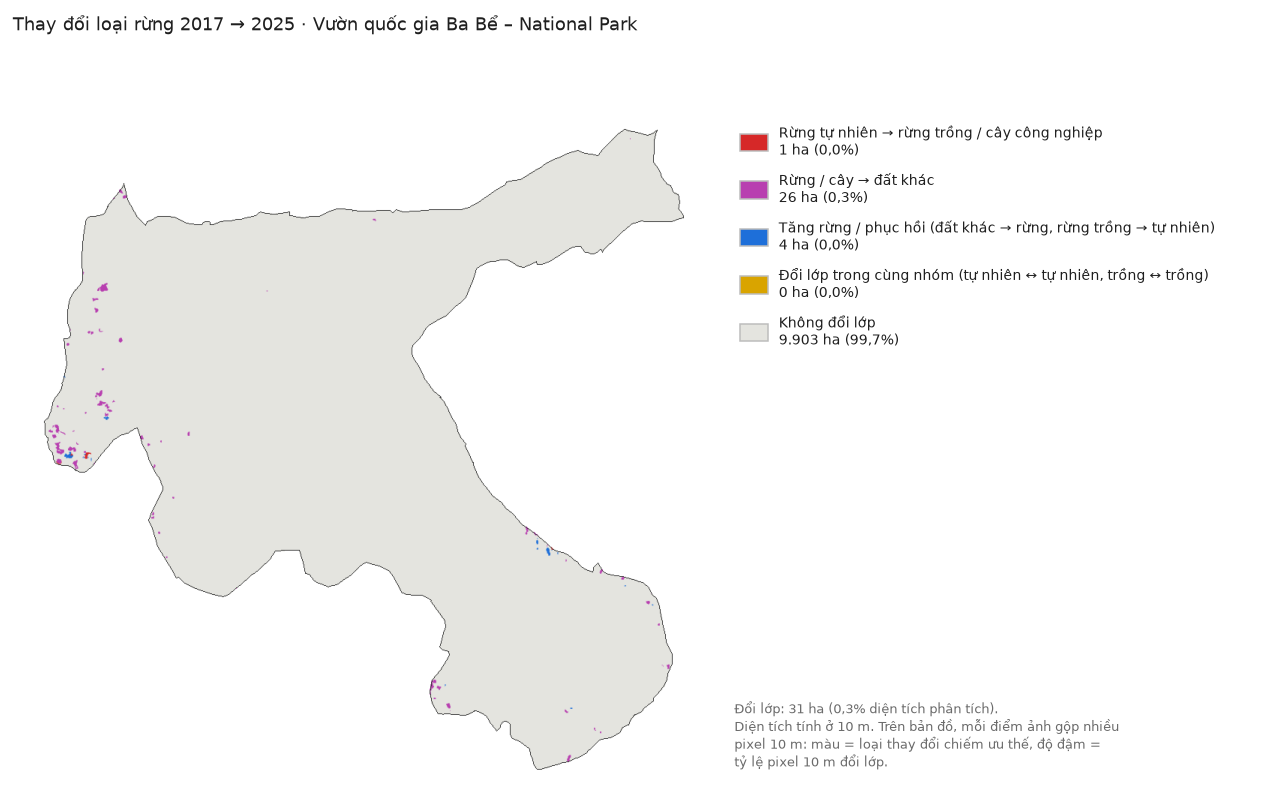

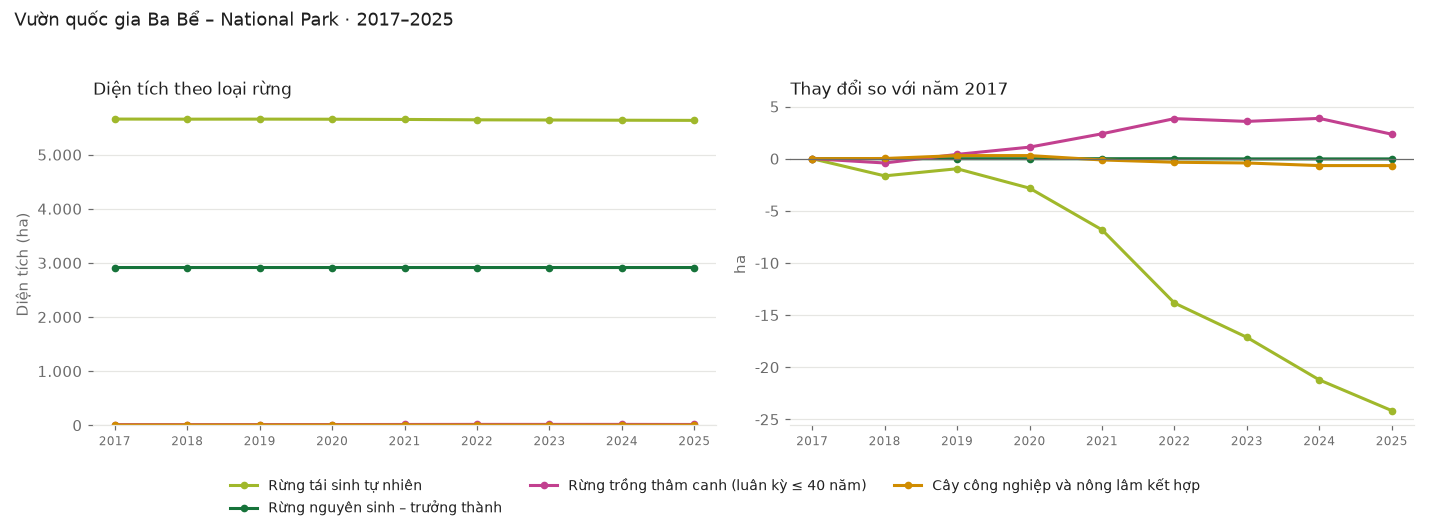

> **Nhận xét (AI, gemini-3.8-flash):** Giai đoạn 2017–2025, diện tích rừng tại Vườn quốc gia Ba Bể duy trì khá ổn định với tỷ lệ che phủ rừng tự nhiên rất cao, chỉ giảm nhẹ từ 86,3% xuống 86,1%. Rừng nguyên sinh – trưởng thành giữ nguyên 2.915 ha, trong khi rừng tái sinh tự nhiên giảm nhiều nhất về diện tích với 24 ha (giảm 0,4%), còn rừng trồng thâm canh tăng mạnh nhất theo tỷ lệ là 20,8% (khoảng 2 ha). Diện tích rừng tái sinh có xu hướng giảm đều đặn qua các năm từ sau năm 2019, tương ứng với mức tăng 23 ha của đất khác. Chênh lệch diện tích này có thể do sai số phân loại ảnh vệ tinh, song khu bảo tồn vẫn cần kiểm tra thực địa tại các vùng rừng tái sinh suy giảm để xác minh nguy cơ tác động ven rìa.

… còn 146 khu khác trong báo cáo HTML


In [11]:
for pa in pas.head(CFG["SHOW_IN_NOTEBOOK"]).itertuples():
    f = figures.get(pa.SITE_ID, {})
    text, reason = observations.get(pa.SITE_ID, (None, ""))
    display(Markdown(f"### {pa.NAME} ({pa.DESIG_ENG}, WDPA {pa.SITE_ID})"))
    if f.get("map"):
        display(Image(filename=str(f["map"])))
    if f.get("change"):
        display(Image(filename=str(f["change"])))
    if f.get("chart"):
        display(Image(filename=str(f["chart"])))
    display(Markdown(f"> **Nhận xét (AI, {MODEL}):** {text}" if text else f"*Chưa có nhận xét AI: {reason}*"))
if len(pas) > CFG["SHOW_IN_NOTEBOOK"]:
    print(f"… còn {len(pas) - CFG['SHOW_IN_NOTEBOOK']} khu khác trong báo cáo HTML")

## 9. Báo cáo HTML

Hai bản cùng nội dung:
- `outputs/bao_cao_ForTy_PA_VN.html`: một file duy nhất, ảnh nhúng sẵn, để gửi hoặc mở offline.
- `docs/index.html` + `docs/img/`: bản cho GitHub Pages (Settings → Pages → nhánh `main`, thư mục `/docs`). Ảnh là file riêng, tải dần khi cuộn tới nên trang mở nhanh.

In [12]:
kw = dict(overlaps_df=ov, failed={**failed, **failed_tr}, model=MODEL, transitions=transitions)
html_path = report.build_report(OUT / "bao_cao_ForTy_PA_VN.html", pas, areas, CFG["YEARS"], figures, observations,
                                embed=CFG["EMBED_IMAGES"], **kw)
print(f"{html_path} ({html_path.stat().st_size / 1e6:.1f} MB)")

pages = report.build_report(CFG["PAGES_DIR"] / "index.html", pas, areas, CFG["YEARS"], figures, observations,
                            embed=False, **kw)
(CFG["PAGES_DIR"] / ".nojekyll").touch()  # serve files as they are, no Jekyll build
img_mb = sum(f.stat().st_size for f in (CFG["PAGES_DIR"] / "img").glob("*.png")) / 1e6
print(f"{pages} ({pages.stat().st_size / 1e6:.1f} MB) + {len(list((CFG['PAGES_DIR'] / 'img').glob('*.png')))} ảnh "
      f"({img_mb:.1f} MB)")

C:\Users\gfd\Documents\Claude\Projects\2026.10.25 nature forest alphaearth map\outputs\bao_cao_ForTy_PA_VN.html (28.2 MB)


C:\Users\gfd\Documents\Claude\Projects\2026.10.25 nature forest alphaearth map\docs\index.html (0.8 MB) + 468 ảnh (20.6 MB)
